# ĐỒ ÁN KHAI PHÁ DỮ LIỆU - PHÂN LOẠI VÀ PHÂN CỤM ĐẬU KHÔ (DRY BEAN DATASET)

---

### Thông tin chung
- **Học phần:** Học phần: Khai thác dữ liệu và ứng dụng (841447)
- **Nhóm 9:** Trương Chí Long (3123410198) & Bùi Anh Đức (3124720016)
- **Giảng viên hướng dẫn:** Nguyễn Thanh Phước
- **Đơn vị:** Trường Đại học Sài Gòn (SGU)
---
- **Đề tài:** Khai phá dữ liệu — Phân loại và Phân cụm 7 giống đậu khô (*Dry Bean Dataset*)
- **Dữ liệu gốc:** 13.611 mẫu hạt đậu khô, 16 đặc trưng hình thái số (kích thước & hình dạng) và 1 nhãn phân lớp `Class` gồm 7 giống: `BARBUNYA`, `BOMBAY`, `CALI`, `DERMASON`, `HOROZ`, `SEKER`, `SIRA` (Koklu & Ozkan, 2020).

---

### Mục tiêu nghiên cứu & Hai câu hỏi cốt lõi (Research Questions)
Dự án áp dụng quy trình khai phá dữ liệu hoàn chỉnh từ nạp dữ liệu, tiền xử lý, phân tích khám phá (EDA) đến mô hình hóa học có giám sát và không giám sát nhằm giải quyết hai câu hỏi nghiên cứu trọng tâm:

1. **RQ1 (Phân loại — Học có giám sát):**
   *Dựa vào nhóm đặc trưng nào — **kích thước** (`Area`, `Perimeter`, ...) hay **hình dạng** (`roundness`, `ShapeFactor`, ...) — để xác định loại đậu chính xác hơn?*
   - **Phương pháp:** Huấn luyện đối chứng 2 thuật toán (`GaussianNB` và `DecisionTreeClassifier`) trên 3 bộ đặc trưng (*Toàn bộ 16*, *Kích thước 8*, *Hình dạng 8*) bằng dữ liệu thô, đánh giá qua **5-fold Stratified Cross-Validation** trên tập Train (80%) để chọn mô hình tối ưu theo **F1-macro CV**, sau đó kiểm chứng trên tập Test (20%) và trích xuất `feature_importances_`.

2. **RQ2 (Phân cụm — Học không giám sát):**
   *Số cụm tối ưu của **K-Means** là bao nhiêu, và các cụm có khớp với **7 loại đậu thật** không?*
   - **Phương pháp:** Chuẩn hóa 16 đặc trưng số bằng `StandardScaler` (tách biệt hoàn toàn nhãn `Class`), chạy `KMeans` với $K \in [2..10]$, chọn $K$ tối ưu bằng phương pháp **Elbow (Inertia)** và **Silhouette Score**; đối chiếu tại $K = 7$ qua bảng chéo **Crosstab**, chỉ số **Adjusted Rand Index (ARI)** và không gian giảm chiều **PCA 2D**.

---

### Tóm tắt công nghệ & Cấu hình môi trường
- **Ngôn ngữ & Thư viện:** Python 3.10+, `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `seaborn`
- **Tính tái lập (Reproducibility):** Cố định hằng số `RANDOM_STATE = 42` xuyên suốt chia tập, CV, Decision Tree, K-Means và PCA.
- **Tiêu chuẩn trực quan hóa:** Style `seaborn-v0_8-whitegrid`, font `DejaVu Sans`, bảng màu cố định `tab10` theo từng giống đậu, xuất ảnh PNG độ phân giải `300 DPI` vào thư mục `outputs/` kèm hiển thị inline (`plt.show()`).

## Phần 1: Khởi tạo môi trường, Hằng số & Nạp dữ liệu

Trong bước này, hệ thống thực hiện:
1. Import đầy đủ các thư viện cho phép (`os`, `sys`, `warnings`, `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`).
2. Cấu hình giao diện trực quan hóa chuẩn (`seaborn-v0_8-whitegrid`, `DejaVu Sans`) và định nghĩa các hằng số toàn cục (`RANDOM_STATE = 42`, `TEST_SIZE = 0.2`, `CV_FOLDS = 5`, `K_RANGE = range(2, 11)`).
3. Phân tách rõ ràng định nghĩa 2 nhóm đặc trưng: **Nhóm Kích thước (8 đặc trưng)** và **Nhóm Hình dạng (8 đặc trưng)**.
4. Đọc tập dữ liệu `dry_beans.csv`, kiểm tra tồn tại tệp và đủ 17 cột bắt buộc, báo cáo kích thước, kiểu dữ liệu và phân bố ban đầu của 7 giống đậu.

In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    classification_report,
    confusion_matrix,
    f1_score,
    silhouette_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

# Cấu hình trực quan hóa mặc định theo DESIGN.md
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["font.family"] = "sans-serif"

# ==============================================================================
# HẰNG SỐ CẤU HÌNH DỰ ÁN
# ==============================================================================
RANDOM_STATE = 42
DATA_PATH = "dry_beans.csv"
OUTPUT_DIR = "outputs"
TEST_SIZE = 0.2
CV_FOLDS = 5
K_RANGE = range(2, 11)

# Tạo thư mục outputs/ nếu chưa tồn tại
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Định nghĩa 2 nhóm đặc trưng hình thái theo PRD.md và ARCHITECTURE.md
# Nhóm kích thước (8 đặc trưng): kích thước cơ bản và các độ đo trục chính/phụ
SIZE_FEATURES = [
    "Area",
    "Perimeter",
    "MajorAxisLength",
    "MinorAxisLength",
    "AspectRation",
    "Eccentricity",
    "ConvexArea",
    "EquivDiameter",
]

# Nhóm hình dạng (8 đặc trưng): các hệ số hình thái, độ lồi, độ nén, độ tròn
SHAPE_FEATURES = [
    "Extent",
    "Solidity",
    "roundness",
    "Compactness",
    "ShapeFactor1",
    "ShapeFactor2",
    "ShapeFactor3",
    "ShapeFactor4",
]

ALL_FEATURES = SIZE_FEATURES + SHAPE_FEATURES
CLASS_COLUMN = "Class"
EXPECTED_COLUMNS = ALL_FEATURES + [CLASS_COLUMN]

# Danh sách 7 lớp đậu khô và bảng màu cố định theo tab10 (DESIGN.md)
CLASS_NAMES = [
    "BARBUNYA",
    "BOMBAY",
    "CALI",
    "DERMASON",
    "HOROZ",
    "SEKER",
    "SIRA",
]

TAB10_PALETTE = sns.color_palette("tab10", len(CLASS_NAMES))
CLASS_COLOR_MAP = dict(zip(CLASS_NAMES, TAB10_PALETTE))

print("Khởi tạo môi trường và hằng số thành công!")
print(f"- RANDOM_STATE  : {RANDOM_STATE}")
print(f"- Nhóm Kích thước ({len(SIZE_FEATURES)}): {SIZE_FEATURES}")
print(f"- Nhóm Hình dạng  ({len(SHAPE_FEATURES)}): {SHAPE_FEATURES}")

Khởi tạo môi trường và hằng số thành công!
- RANDOM_STATE  : 42
- Nhóm Kích thước (8): ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter']
- Nhóm Hình dạng  (8): ['Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']


In [ ]:
def load_data(file_path: str = DATA_PATH) -> pd.DataFrame:
    """Đọc tập dữ liệu CSV, kiểm tra cấu trúc cột và báo cáo thông tin cơ bản."""
    print("=" * 70)
    print("BƯỚC 1: NẠP DỮ LIỆU & KIỂM TRA TOÀN VẸN")
    print("=" * 70)

    if not os.path.exists(file_path):
        print(
            f"[LỖI] Không tìm thấy file dữ liệu tại: '{file_path}'.\n"
            "Hướng dẫn khắc phục: Đặt file 'dry_beans.csv' cùng thư mục với notebook."
        )
        sys.exit(1)

    try:
        df = pd.read_csv(file_path)
    except Exception as exc:
        print(
            f"[LỖI] Không thể đọc file CSV '{file_path}': {exc}\n"
            "Hướng dẫn khắc phục: Kiểm tra quyền đọc file hoặc định dạng CSV."
        )
        sys.exit(1)

    missing_columns = [col for col in EXPECTED_COLUMNS if col not in df.columns]
    if missing_columns:
        print(
            f"[LỖI] Dữ liệu thiếu các cột bắt buộc: {missing_columns}.\n"
            f"Tổng số cột hiện có: {len(df.columns)}/{len(EXPECTED_COLUMNS)} cột.\n"
            "Hướng dẫn khắc phục: Đảm bảo file CSV đủ 16 đặc trưng và cột 'Class'."
        )
        sys.exit(1)

    print(f"- Đọc thành công file: '{file_path}'")
    print(f"- Kích thước tập dữ liệu thô: {df.shape[0]:,} dòng, {df.shape[1]} cột")

    print("\nKiểu dữ liệu các cột:")
    for col in df.columns:
        print(f"  + {col:<18}: {df[col].dtype}")

    print("\nPhân bố số lượng các lớp mục tiêu ('Class') ban đầu:")
    class_counts = df[CLASS_COLUMN].value_counts()
    class_ratios = df[CLASS_COLUMN].value_counts(normalize=True) * 100
    for cls in class_counts.index:
        print(f"  + {cls:<10}: {class_counts[cls]:>5} mẫu ({class_ratios[cls]:>6.2f}%)")

    return df


df_raw = load_data(DATA_PATH)

BƯỚC 1: NẠP DỮ LIỆU & KIỂM TRA TOÀN VẸN (TASK T2)
- Đọc thành công file: 'dry_beans.csv'
- Kích thước tập dữ liệu thô: 13,611 dòng, 17 cột

Kiểu dữ liệu các cột:
  + Area              : int64
  + Perimeter         : float64
  + MajorAxisLength   : float64
  + MinorAxisLength   : float64
  + AspectRation      : float64
  + Eccentricity      : float64
  + ConvexArea        : int64
  + EquivDiameter     : float64
  + Extent            : float64
  + Solidity          : float64
  + roundness         : float64
  + Compactness       : float64
  + ShapeFactor1      : float64
  + ShapeFactor2      : float64
  + ShapeFactor3      : float64
  + ShapeFactor4      : float64
  + Class             : str

Phân bố số lượng các lớp mục tiêu ('Class') ban đầu:
  + DERMASON  :  3546 mẫu ( 26.05%)
  + SIRA      :  2636 mẫu ( 19.37%)
  + SEKER     :  2027 mẫu ( 14.89%)
  + HOROZ     :  1928 mẫu ( 14.17%)
  + CALI      :  1630 mẫu ( 11.98%)
  + BARBUNYA  :  1322 mẫu (  9.71%)
  + BOMBAY    :   522 mẫu (  3.8

## Phần 2: Tiền xử lý dữ liệu

Quy trình tiền xử lý:
1. **Kiểm tra giá trị khuyết thiếu (Missing Values):** Đảm bảo không có giá trị `NaN` gây sai lệch cho mô hình.
2. **Loại bỏ dòng trùng lặp hoàn toàn (Duplicates):** Tránh hiện tượng rò rỉ dữ liệu giữa tập Train/Test và thiên lệch trọng số mẫu.
3. **Phát hiện ngoại lai bằng phương pháp IQR ($1.5 \times \text{IQR}$):**
   - Tính biên dưới $Q_1 - 1.5 \times \text{IQR}$ và biên trên $Q_3 + 1.5 \times \text{IQR}$ cho cả 16 đặc trưng số.
   - **Nguyên tắc xử lý:** **Tuyệt đối giữ nguyên toàn bộ mẫu ngoại lai** (không xóa), bởi trong bài toán phân loại sinh học nhiều giống đậu kích thước khác biệt lớn (như `BOMBAY` so với `DERMASON`), các điểm vượt biên IQR toàn cục chính là đặc trưng nhận diện tự nhiên của giống đậu hiếm, không phải lỗi thu thập dữ liệu.
   - **Không chuẩn hóa ở bước này:** Dữ liệu thô được bảo toàn cho `GaussianNB` và `DecisionTreeClassifier` theo Điều cấm số 5.

In [ ]:
def preprocess(df: pd.DataFrame) -> pd.DataFrame:
    """Tiền xử lý dữ liệu: kiểm tra thiếu, loại trùng và thống kê ngoại lai IQR."""
    print("=" * 70)
    print("BƯỚC 2: TIỀN XỬ LÝ DỮ LIỆU")
    print("=" * 70)

    # 1. Kiểm tra giá trị thiếu
    null_counts = df.isnull().sum()
    total_nulls = int(null_counts.sum())
    print(f"- Kiểm tra giá trị khuyết thiếu (NaN): {total_nulls} giá trị thiếu.")
    if total_nulls > 0:
        for col, cnt in null_counts[null_counts > 0].items():
            print(f"  + {col}: {cnt} dòng thiếu")
    else:
        print("  -> Dữ liệu hoàn toàn đầy đủ, không có giá trị thiếu.")

    # 2. Kiểm tra và loại bỏ dòng trùng lặp hoàn toàn
    num_duplicates = int(df.duplicated().sum())
    print(f"\n- Kiểm tra dòng trùng lặp: Phát hiện {num_duplicates} dòng trùng.")
    if num_duplicates > 0:
        df_clean = df.drop_duplicates().copy().reset_index(drop=True)
        print(
            f"  -> Đã loại bỏ {num_duplicates} dòng trùng lặp hoàn toàn.\n"
            f"  -> Kích thước dữ liệu sạch: {df_clean.shape[0]:,} dòng, "
            f"{df_clean.shape[1]} cột."
        )
    else:
        df_clean = df.copy()

    # 3. Phát hiện ngoại lai bằng IQR (tuyệt đối giữ nguyên, chỉ báo cáo)
    print("\n- Báo cáo ngoại lai theo phương pháp IQR (ngưỡng 1.5 * IQR):")
    any_outlier_mask = pd.Series(False, index=df_clean.index)

    for feature in ALL_FEATURES:
        q1 = df_clean[feature].quantile(0.25)
        q3 = df_clean[feature].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        is_outlier = (df_clean[feature] < lower_bound) | (
            df_clean[feature] > upper_bound
        )
        count_outliers = int(is_outlier.sum())
        any_outlier_mask |= is_outlier
        ratio = (count_outliers / len(df_clean)) * 100
        print(
            f"  + {feature:<16}: {count_outliers:>4} ngoại lai ({ratio:>5.2f}%) "
            f"[Khoảng hợp lệ: {lower_bound:.4f} đến {upper_bound:.4f}]"
        )

    total_outlier_rows = int(any_outlier_mask.sum())
    outlier_pct = (total_outlier_rows / len(df_clean)) * 100
    print(
        f"\n  => Tổng số mẫu có ít nhất 1 đặc trưng ngoại lai: "
        f"{total_outlier_rows:,}/{len(df_clean):,} mẫu ({outlier_pct:.2f}%)."
    )
    print(
        "  => QUYẾT ĐỊNH XỬ LÝ: Tuyệt đối giữ nguyên toàn bộ ngoại lai vì đây là\n"
        "     biến thiên sinh học tự nhiên giữa các giống đậu, không phải lỗi dữ liệu."
    )

    return df_clean


df_clean = preprocess(df_raw)

BƯỚC 2: TIỀN XỬ LÝ DỮ LIỆU (TASK T3)
- Kiểm tra giá trị khuyết thiếu (NaN): 0 giá trị thiếu.
  -> Dữ liệu hoàn toàn đầy đủ, không có giá trị thiếu.

- Kiểm tra dòng trùng lặp: Phát hiện 68 dòng trùng.
  -> Đã loại bỏ 68 dòng trùng lặp hoàn toàn.
  -> Kích thước dữ liệu sạch: 13,543 dòng, 17 cột.

- Báo cáo ngoại lai theo phương pháp IQR (ngưỡng 1.5 * IQR):
  + Area            :  551 ngoại lai ( 4.07%) [Khoảng hợp lệ: -1366.7500 đến 99031.2500]
  + Perimeter       :  500 ngoại lai ( 3.69%) [Khoảng hợp lệ: 292.3552 đến 1388.0213]
  + MajorAxisLength :  379 ngoại lai ( 2.80%) [Khoảng hợp lệ: 68.2483 đến 561.1510]
  + MinorAxisLength :  567 ngoại lai ( 4.19%) [Khoảng hợp lệ: 113.8478 đến 279.2840]
  + AspectRation    :  485 ngoại lai ( 3.58%) [Khoảng hợp lệ: 1.0208 đến 2.1138]
  + Eccentricity    :  833 ngoại lai ( 6.15%) [Khoảng hợp lệ: 0.5734 đến 0.9515]
  + ConvexArea      :  549 ngoại lai ( 4.05%) [Khoảng hợp lệ: -1857.5000 đến 100890.5000]
  + EquivDiameter   :  526 ngoại lai ( 3.88%)

## Phần 3: Phân tích Khám phá Dữ liệu - EDA

### 3.1. Thống kê mô tả & Biểu đồ phân bố lớp
Tính toán các đại lượng thống kê mô tả cơ bản (`Mean`, `Std`, `Median`, `Q1`, `Q3`) cho toàn bộ 16 đặc trưng số trên 13.543 mẫu sạch và trực quan hóa phân bố số lượng của 7 giống đậu bằng bảng màu `tab10` cố định (`01_phan_bo_lop.png`).

BẢNG THỐNG KÊ MÔ TẢ 16 ĐẶC TRƯNG SỐ (N = 13.543 MẪU SẠCH)
----------------------------------------------------------------------------------------
Đặc trưng          |        Mean |         Std |      Median |    Q1 (25%) |    Q3 (75%)
----------------------------------------------------------------------------------------
Area               |  53048.4604 |  29392.4383 |  44580.0000 |  36282.5000 |  61382.0000
Perimeter          |    854.9934 |    214.7227 |    793.8960 |    703.2300 |    977.1465
MajorAxisLength    |    319.8956 |     85.8093 |    296.4046 |    253.0868 |    376.3125
MinorAxisLength    |    202.3653 |     45.0516 |    192.4911 |    175.8864 |    217.2454
AspectRation       |      1.5811 |      0.2452 |      1.5499 |      1.4307 |      1.7039
Eccentricity       |      0.7503 |      0.0919 |      0.7640 |      0.7151 |      0.8097
ConvexArea         |  53767.9867 |  29844.2485 |  45122.0000 |  36673.0000 |  62360.0000
EquivDiameter      |    253.0341 |     59.3077 |    

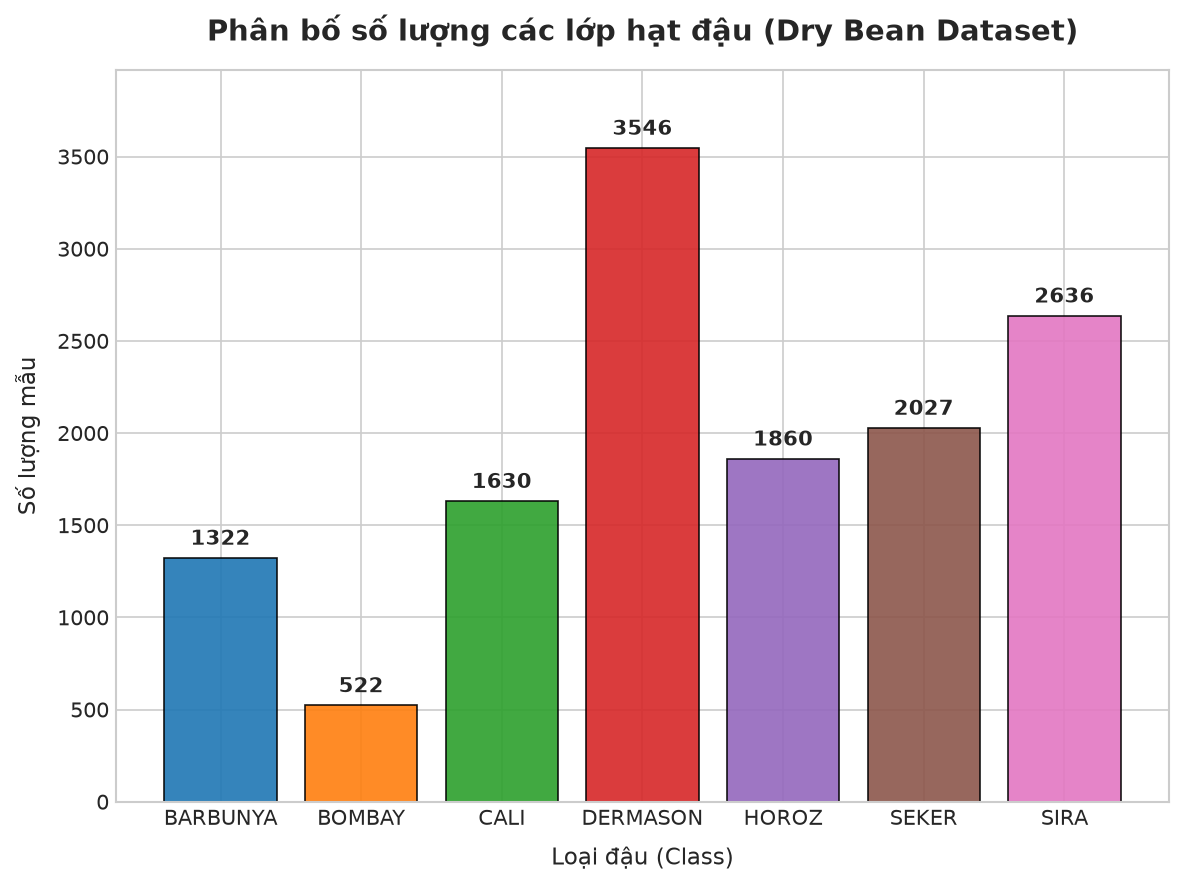

In [4]:
def compute_descriptive_statistics(df: pd.DataFrame) -> pd.DataFrame:
    """Tính toán và in bảng thống kê mô tả (Mean, Std, Median, Q1, Q3)."""
    print("=" * 70)
    print("BẢNG THỐNG KÊ MÔ TẢ 16 ĐẶC TRƯNG SỐ (N = 13.543 MẪU SẠCH)")
    print("=" * 70)

    stats_list = []
    for col in ALL_FEATURES:
        s = df[col]
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        stats_list.append(
            {
                "Đặc trưng": col,
                "Mean": s.mean(),
                "Std": s.std(),
                "Median": s.median(),
                "Q1 (25%)": q1,
                "Q3 (75%)": q3,
                "IQR": q3 - q1,
                "Min": s.min(),
                "Max": s.max(),
            }
        )

    stats_df = pd.DataFrame(stats_list)
    header = (
        f"{'Đặc trưng':<18} | {'Mean':>11} | {'Std':>11} | "
        f"{'Median':>11} | {'Q1 (25%)':>11} | {'Q3 (75%)':>11}"
    )
    print("-" * len(header))
    print(header)
    print("-" * len(header))
    for _, row in stats_df.iterrows():
        print(
            f"{row['Đặc trưng']:<18} | "
            f"{row['Mean']:>11.4f} | "
            f"{row['Std']:>11.4f} | "
            f"{row['Median']:>11.4f} | "
            f"{row['Q1 (25%)']:>11.4f} | "
            f"{row['Q3 (75%)']:>11.4f}"
        )
    print("-" * len(header))
    return stats_df


def plot_class_distribution(df: pd.DataFrame, output_dir: str = OUTPUT_DIR) -> None:
    """Vẽ Biểu đồ 01: Phân bố 7 lớp đậu khô (tab10, DPI 300)."""
    class_counts = df[CLASS_COLUMN].value_counts()
    counts = [int(class_counts.get(cls, 0)) for cls in CLASS_NAMES]
    colors = [CLASS_COLOR_MAP[cls] for cls in CLASS_NAMES]

    fig, ax = plt.subplots(figsize=(8, 6))
    bars = ax.bar(
        CLASS_NAMES,
        counts,
        color=colors,
        edgecolor="black",
        linewidth=0.8,
        alpha=0.9,
    )
    ax.bar_label(bars, fmt="%d", padding=4, fontsize=10, fontweight="bold")

    ax.set_title(
        "Phân bố số lượng các lớp hạt đậu (Dry Bean Dataset)",
        fontsize=14,
        fontweight="bold",
        pad=14,
    )
    ax.set_xlabel("Loại đậu (Class)", fontsize=11, labelpad=8)
    ax.set_ylabel("Số lượng mẫu", fontsize=11, labelpad=8)
    ax.tick_params(axis="both", labelsize=10)
    ax.set_ylim(0, max(counts) * 1.12)
    plt.tight_layout()

    out_path = os.path.join(output_dir, "01_phan_bo_lop.png")
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    print(f"- Đã lưu biểu đồ: '{out_path}' (DPI 300)")
    plt.show()
    plt.close(fig)


stats_df = compute_descriptive_statistics(df_clean)
plot_class_distribution(df_clean)

### 3.2. Trực quan hóa đơn biến
Quan sát hình thái phân bố xác suất và điểm ngoại lai trên toàn bộ 16 đặc trưng số qua lưới $4 \times 4$ ($16 \times 12$ inch):
- **Biểu đồ 02 (`02_histogram_dac_trung.png`):** Histogram kết hợp đường cong mật độ KDE.
- **Biểu đồ 03 (`03_boxplot_ngoai_lai.png`):** Boxplot hiển thị chi tiết phân vị và các điểm ngoại lai vượt ngưỡng IQR.

- Đã lưu biểu đồ: 'outputs\02_histogram_dac_trung.png' (DPI 300)
- Đã lưu biểu đồ: 'outputs\03_boxplot_ngoai_lai.png' (DPI 300)


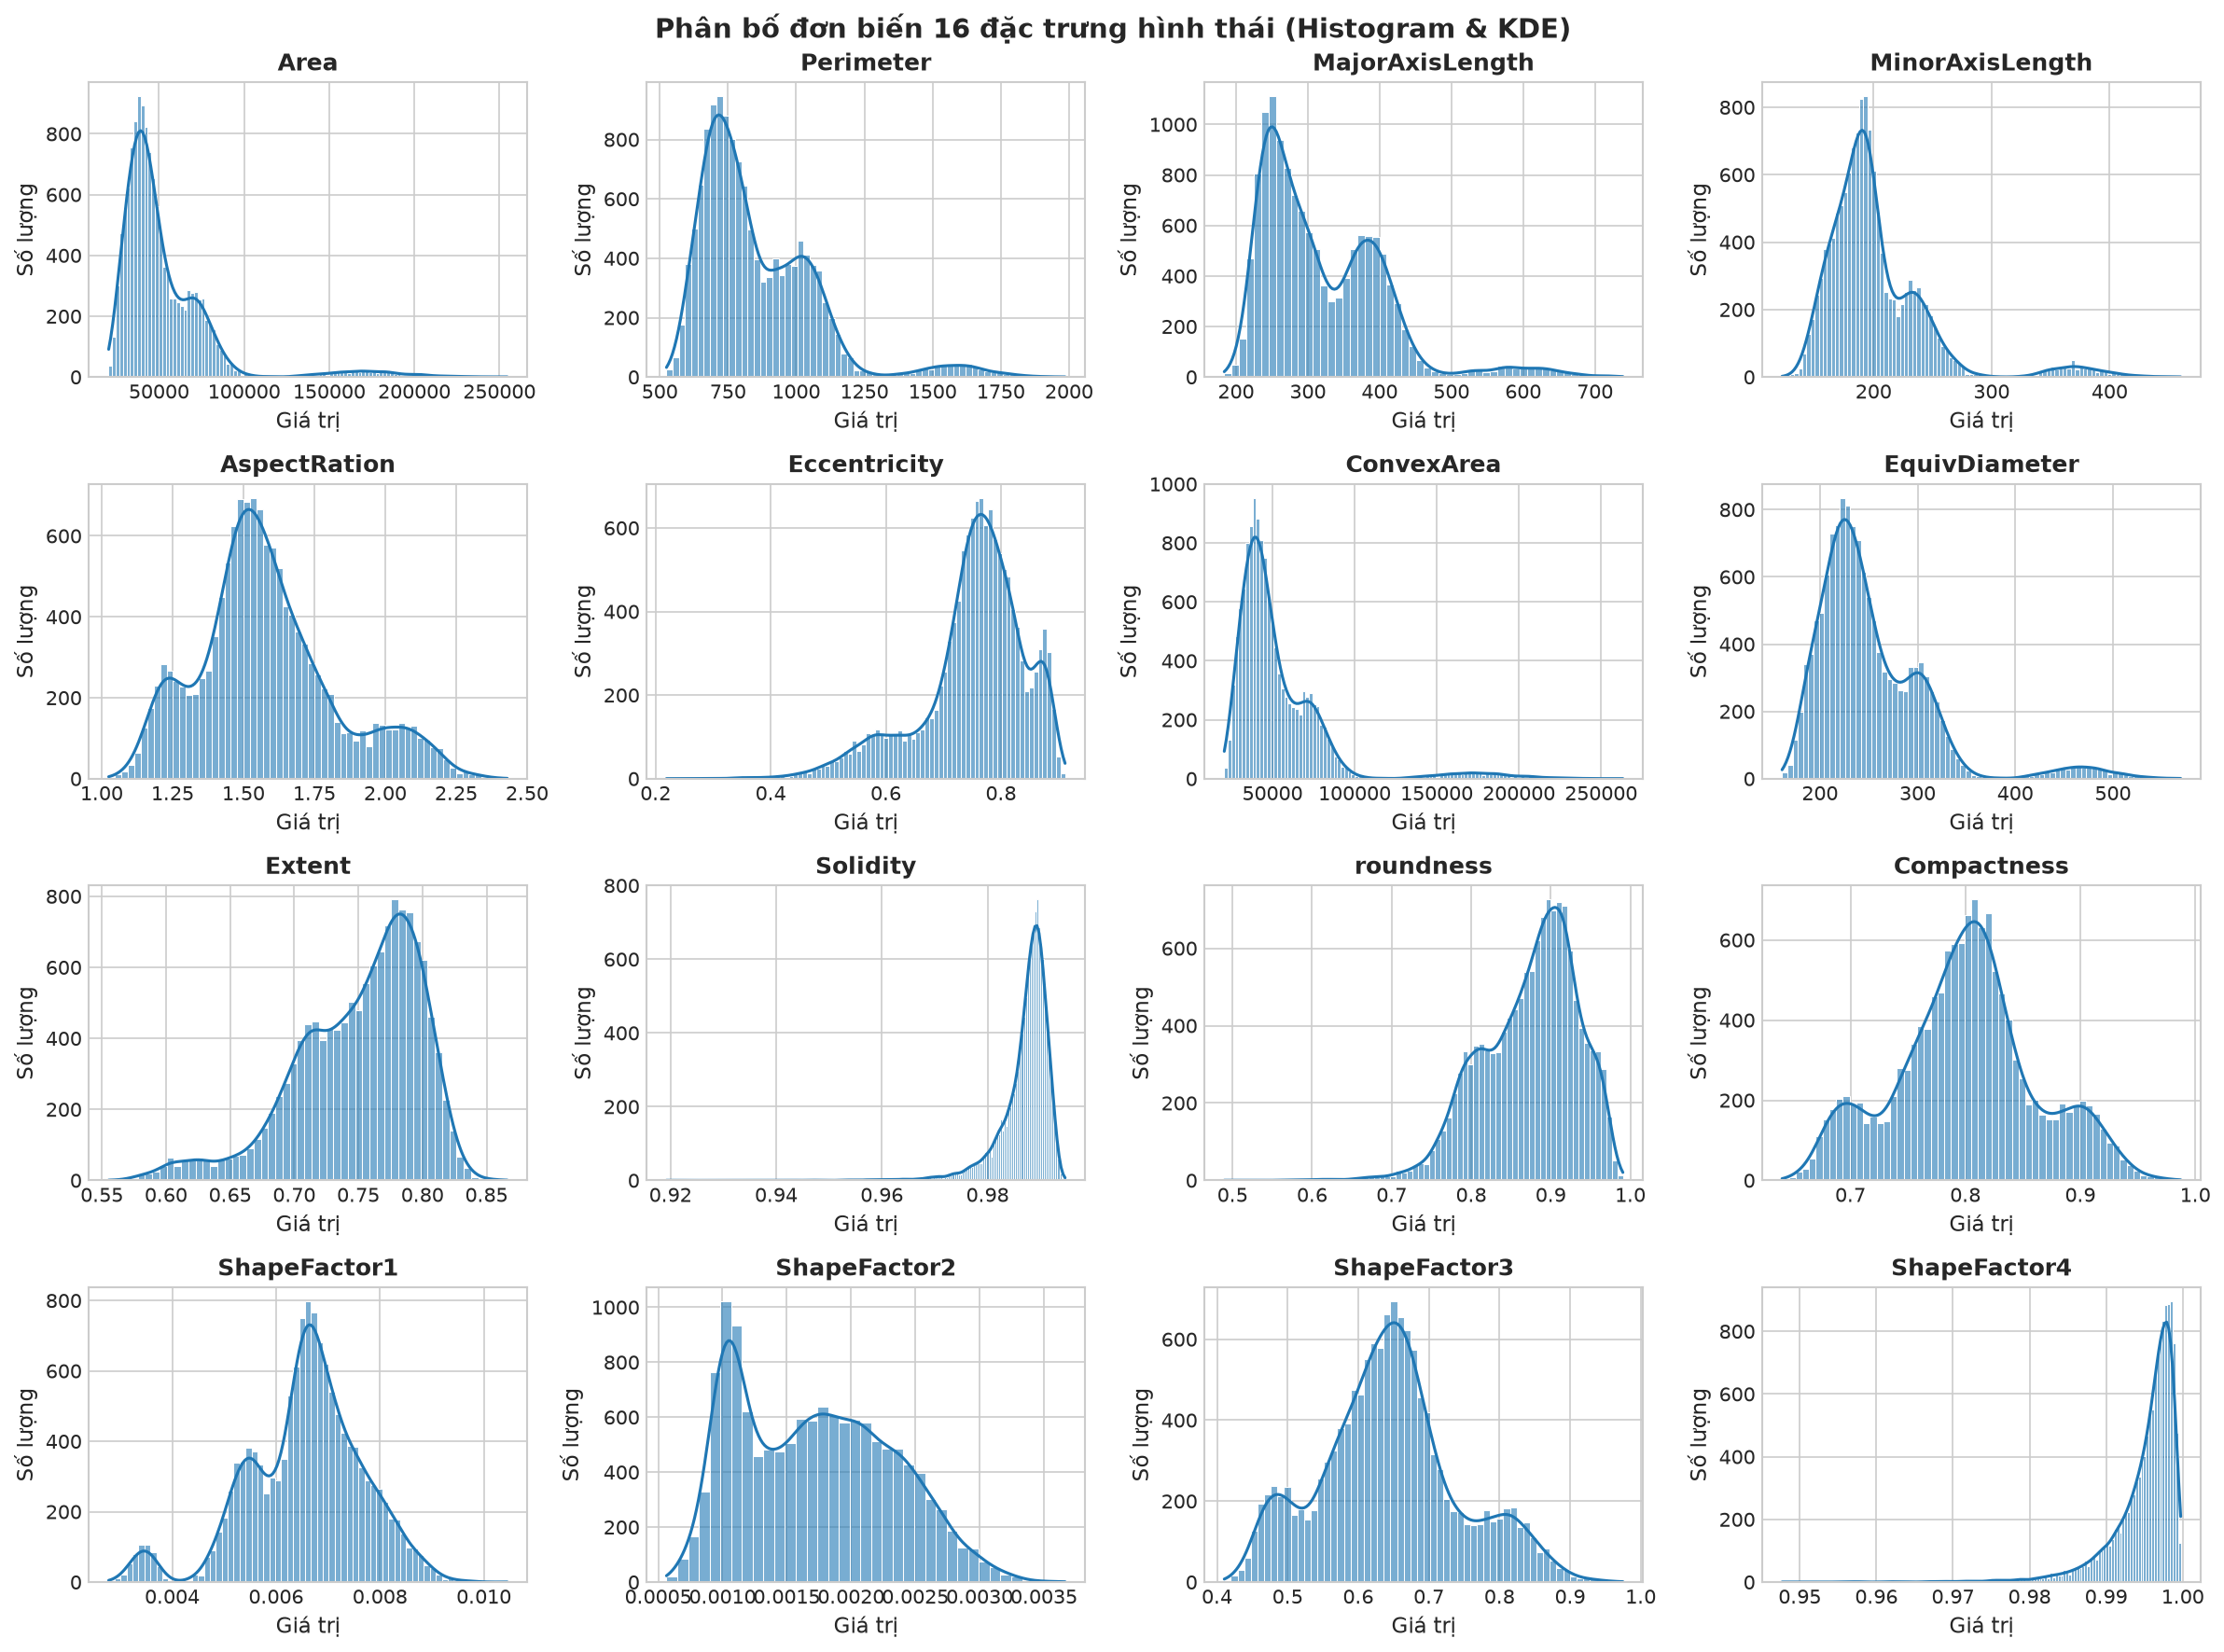

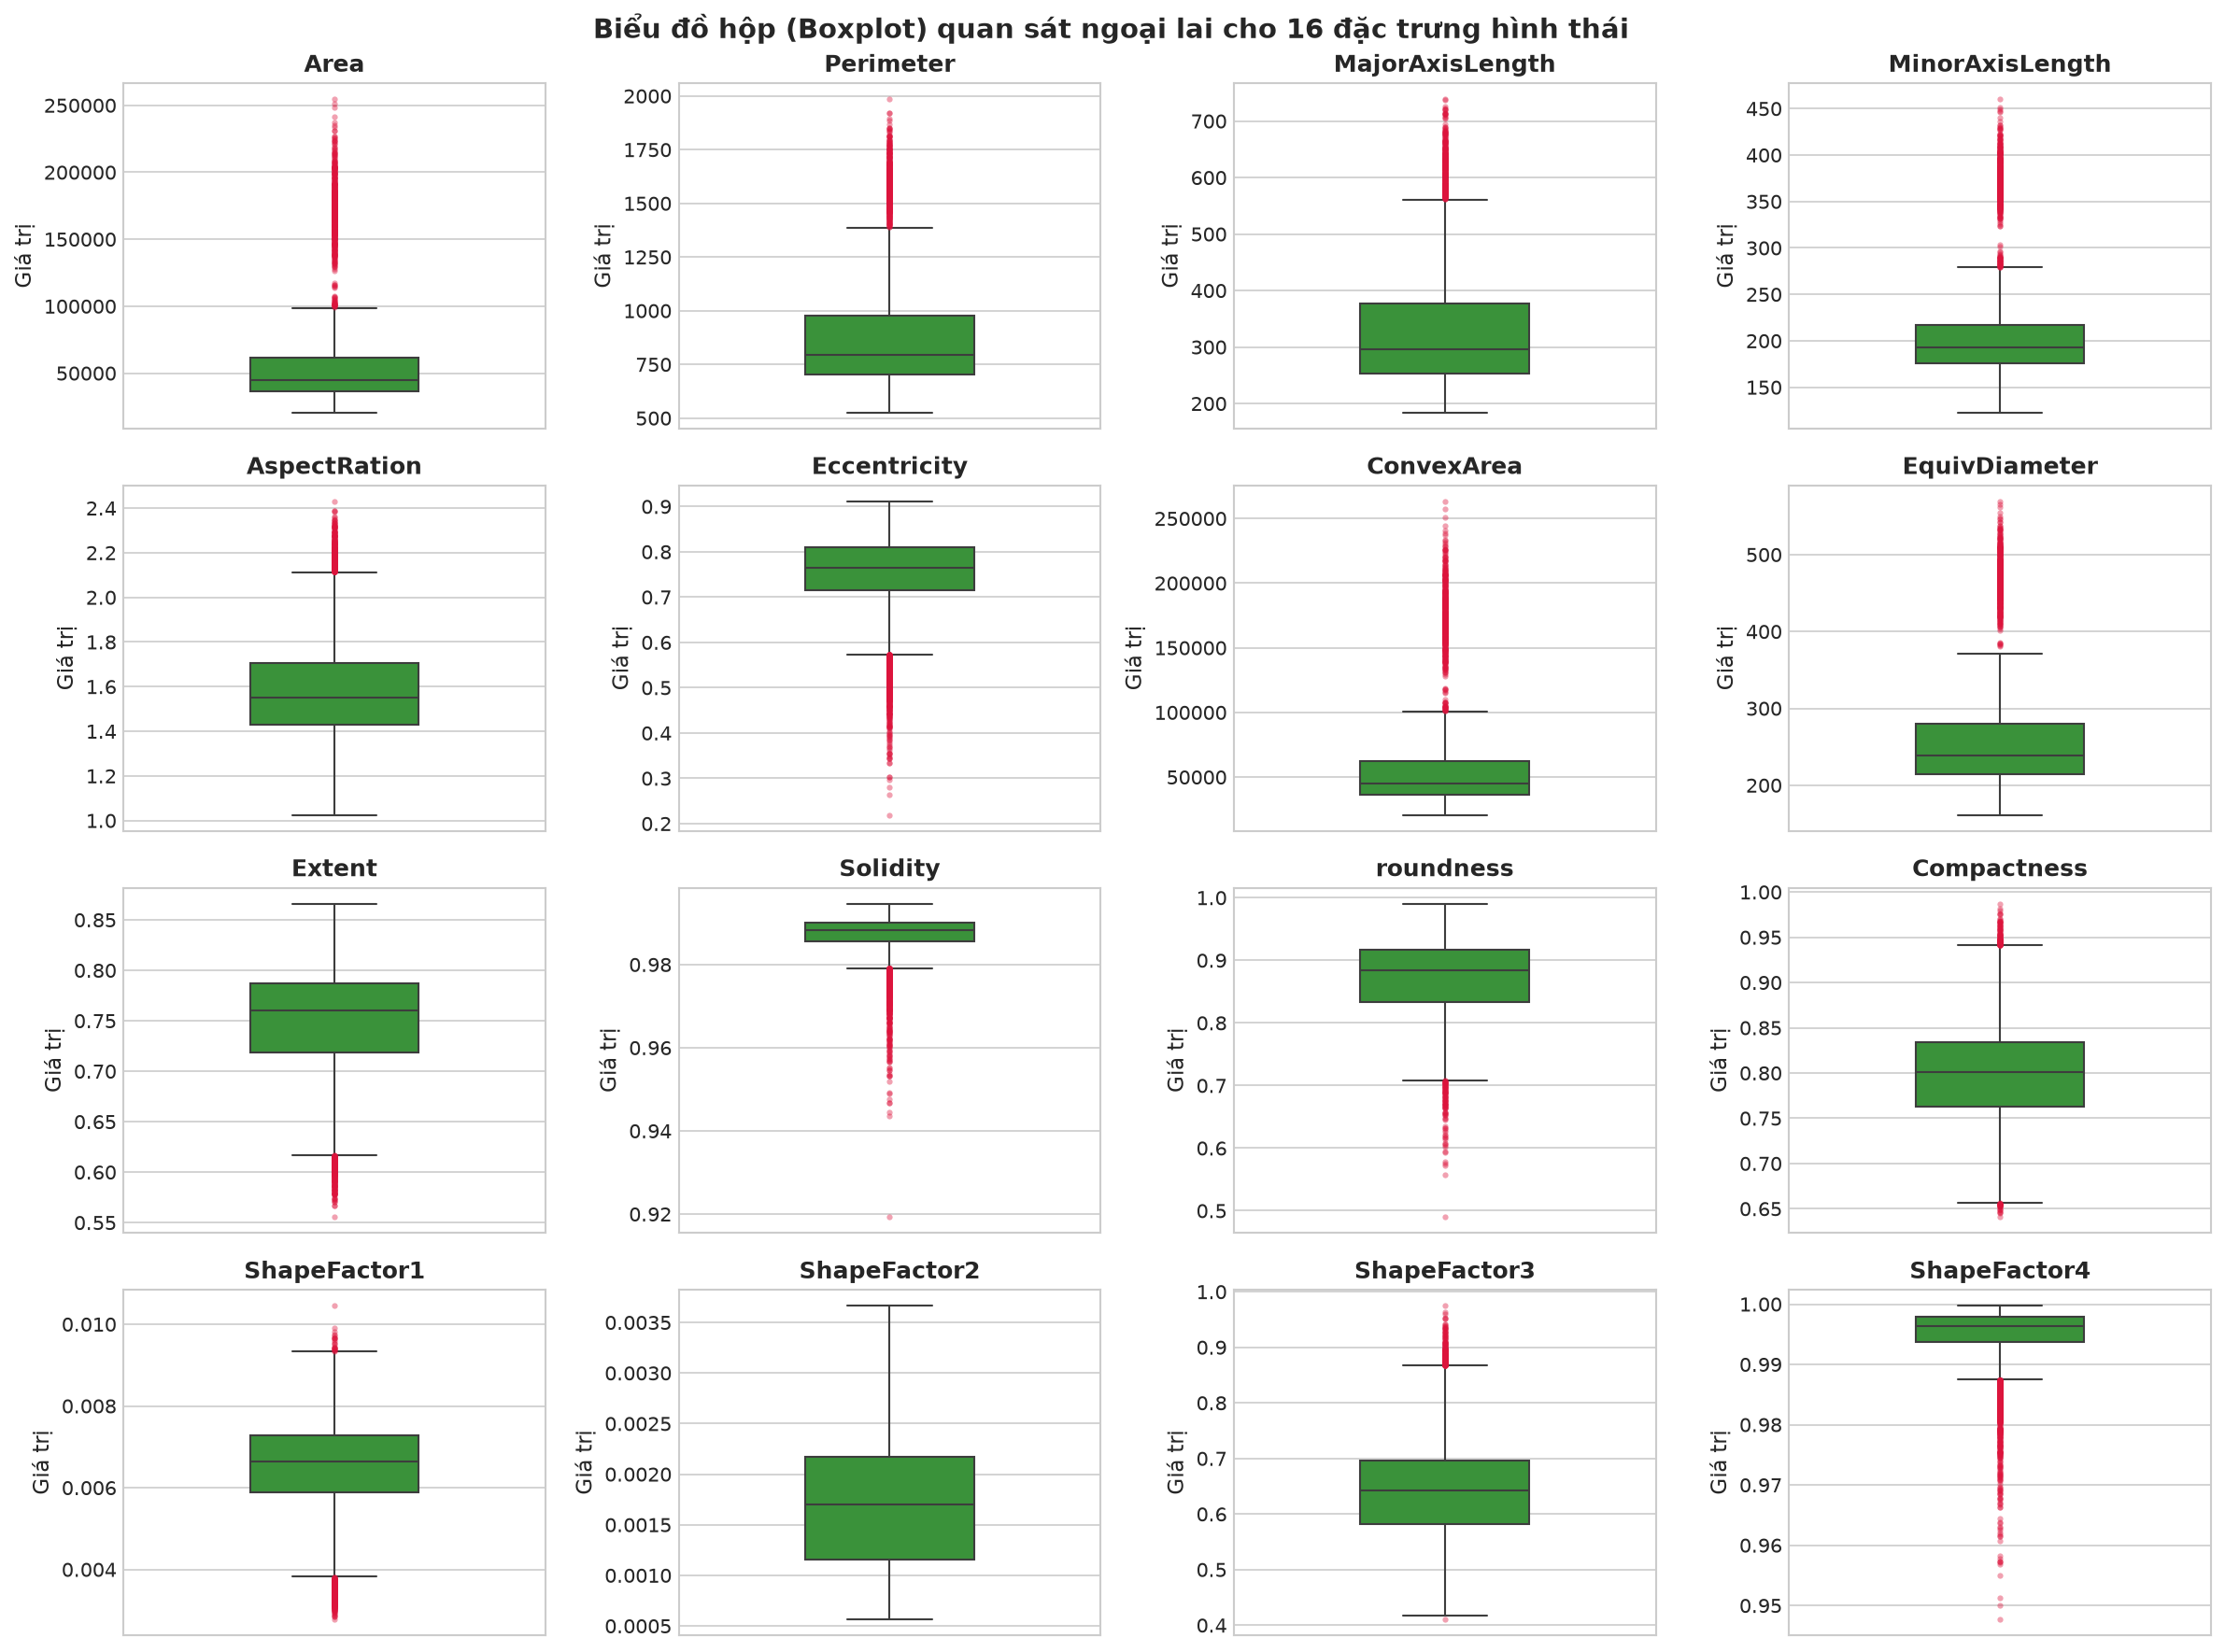

In [5]:
def plot_univariate_charts(df: pd.DataFrame, output_dir: str = OUTPUT_DIR) -> None:
    """Vẽ lưới 4x4 Biểu đồ 02 (Histogram + KDE) và Biểu đồ 03 (Boxplot)."""
    # 1. Biểu đồ 02: Histogram + KDE
    fig1, axes1 = plt.subplots(4, 4, figsize=(16, 12))
    axes1 = axes1.flatten()

    for idx, feature in enumerate(ALL_FEATURES):
        ax = axes1[idx]
        sns.histplot(
            df[feature],
            kde=True,
            ax=ax,
            color="#1f77b4",
            edgecolor="white",
            linewidth=0.5,
            alpha=0.6,
        )
        ax.set_title(feature, fontsize=12, fontweight="bold")
        ax.set_xlabel("Giá trị", fontsize=11)
        ax.set_ylabel("Số lượng", fontsize=11)
        ax.tick_params(axis="both", labelsize=10)

    fig1.suptitle(
        "Phân bố đơn biến 16 đặc trưng hình thái (Histogram & KDE)",
        fontsize=14,
        fontweight="bold",
    )
    plt.tight_layout()
    out_hist = os.path.join(output_dir, "02_histogram_dac_trung.png")
    fig1.savefig(out_hist, dpi=300, bbox_inches="tight")
    print(f"- Đã lưu biểu đồ: '{out_hist}' (DPI 300)")
    plt.show()
    plt.close(fig1)

    # 2. Biểu đồ 03: Boxplot 16 đặc trưng
    fig2, axes2 = plt.subplots(4, 4, figsize=(16, 12))
    axes2 = axes2.flatten()

    for idx, feature in enumerate(ALL_FEATURES):
        ax = axes2[idx]
        sns.boxplot(
            y=df[feature],
            ax=ax,
            color="#2ca02c",
            width=0.4,
            fliersize=3,
            flierprops=dict(
                marker="o",
                markerfacecolor="crimson",
                markeredgecolor="none",
                alpha=0.4,
            ),
        )
        ax.set_title(feature, fontsize=12, fontweight="bold")
        ax.set_ylabel("Giá trị", fontsize=11)
        ax.tick_params(axis="both", labelsize=10)

    fig2.suptitle(
        "Biểu đồ hộp (Boxplot) quan sát ngoại lai cho 16 đặc trưng hình thái",
        fontsize=14,
        fontweight="bold",
    )
    plt.tight_layout()
    out_box = os.path.join(output_dir, "03_boxplot_ngoai_lai.png")
    fig2.savefig(out_box, dpi=300, bbox_inches="tight")
    print(f"- Đã lưu biểu đồ: '{out_box}' (DPI 300)")
    plt.show()
    plt.close(fig2)


plot_univariate_charts(df_clean)

### 3.3. Trực quan hóa đa biến & Phân tích tương quan
- Tính ma trận hệ số tương quan Pearson giữa 16 đặc trưng và lọc danh sách các cặp đặc trưng có tương quan rất cao ($|r| > 0.9$) để nhận diện hiện tượng đa cộng tuyến.
- **Biểu đồ 04 (`04_ma_tran_tuong_quan.png`):** Heatmap ma trận tương quan với bảng màu `coolwarm` (`vmin=-1`, `vmax=1`, `center=0`).
- **Biểu đồ 05 (`05_boxplot_theo_lop.png`):** So sánh phân bố 3 đặc trưng tiêu biểu (`Area`, `AspectRation`, `ShapeFactor1`) qua 7 giống đậu bằng bảng màu `tab10`.

DANH SÁCH CÁC CẶP ĐẶC TRƯNG TƯƠNG QUAN CAO (|r| > 0.9): 21 cặp
--------------------------------------------------------------------------
STT  | Đặc trưng 1      - Đặc trưng 2      |   Hệ số r | Mức độ tương quan
--------------------------------------------------------------------------
1    | Area             - ConvexArea       |    0.9999 | Đồng biến rất mạnh
2    | Compactness      - ShapeFactor3     |    0.9987 | Đồng biến rất mạnh
3    | Perimeter        - EquivDiameter    |    0.9915 | Đồng biến rất mạnh
4    | AspectRation     - Compactness      |   -0.9876 | Nghịch biến rất mạnh
5    | ConvexArea       - EquivDiameter    |    0.9853 | Đồng biến rất mạnh
6    | Area             - EquivDiameter    |    0.9850 | Đồng biến rất mạnh
7    | Eccentricity     - ShapeFactor3     |   -0.9811 | Nghịch biến rất mạnh
8    | AspectRation     - ShapeFactor3     |   -0.9785 | Nghịch biến rất mạnh
9    | Perimeter        - MajorAxisLength  |    0.9776 | Đồng biến rất mạnh
10   | Eccentricity   

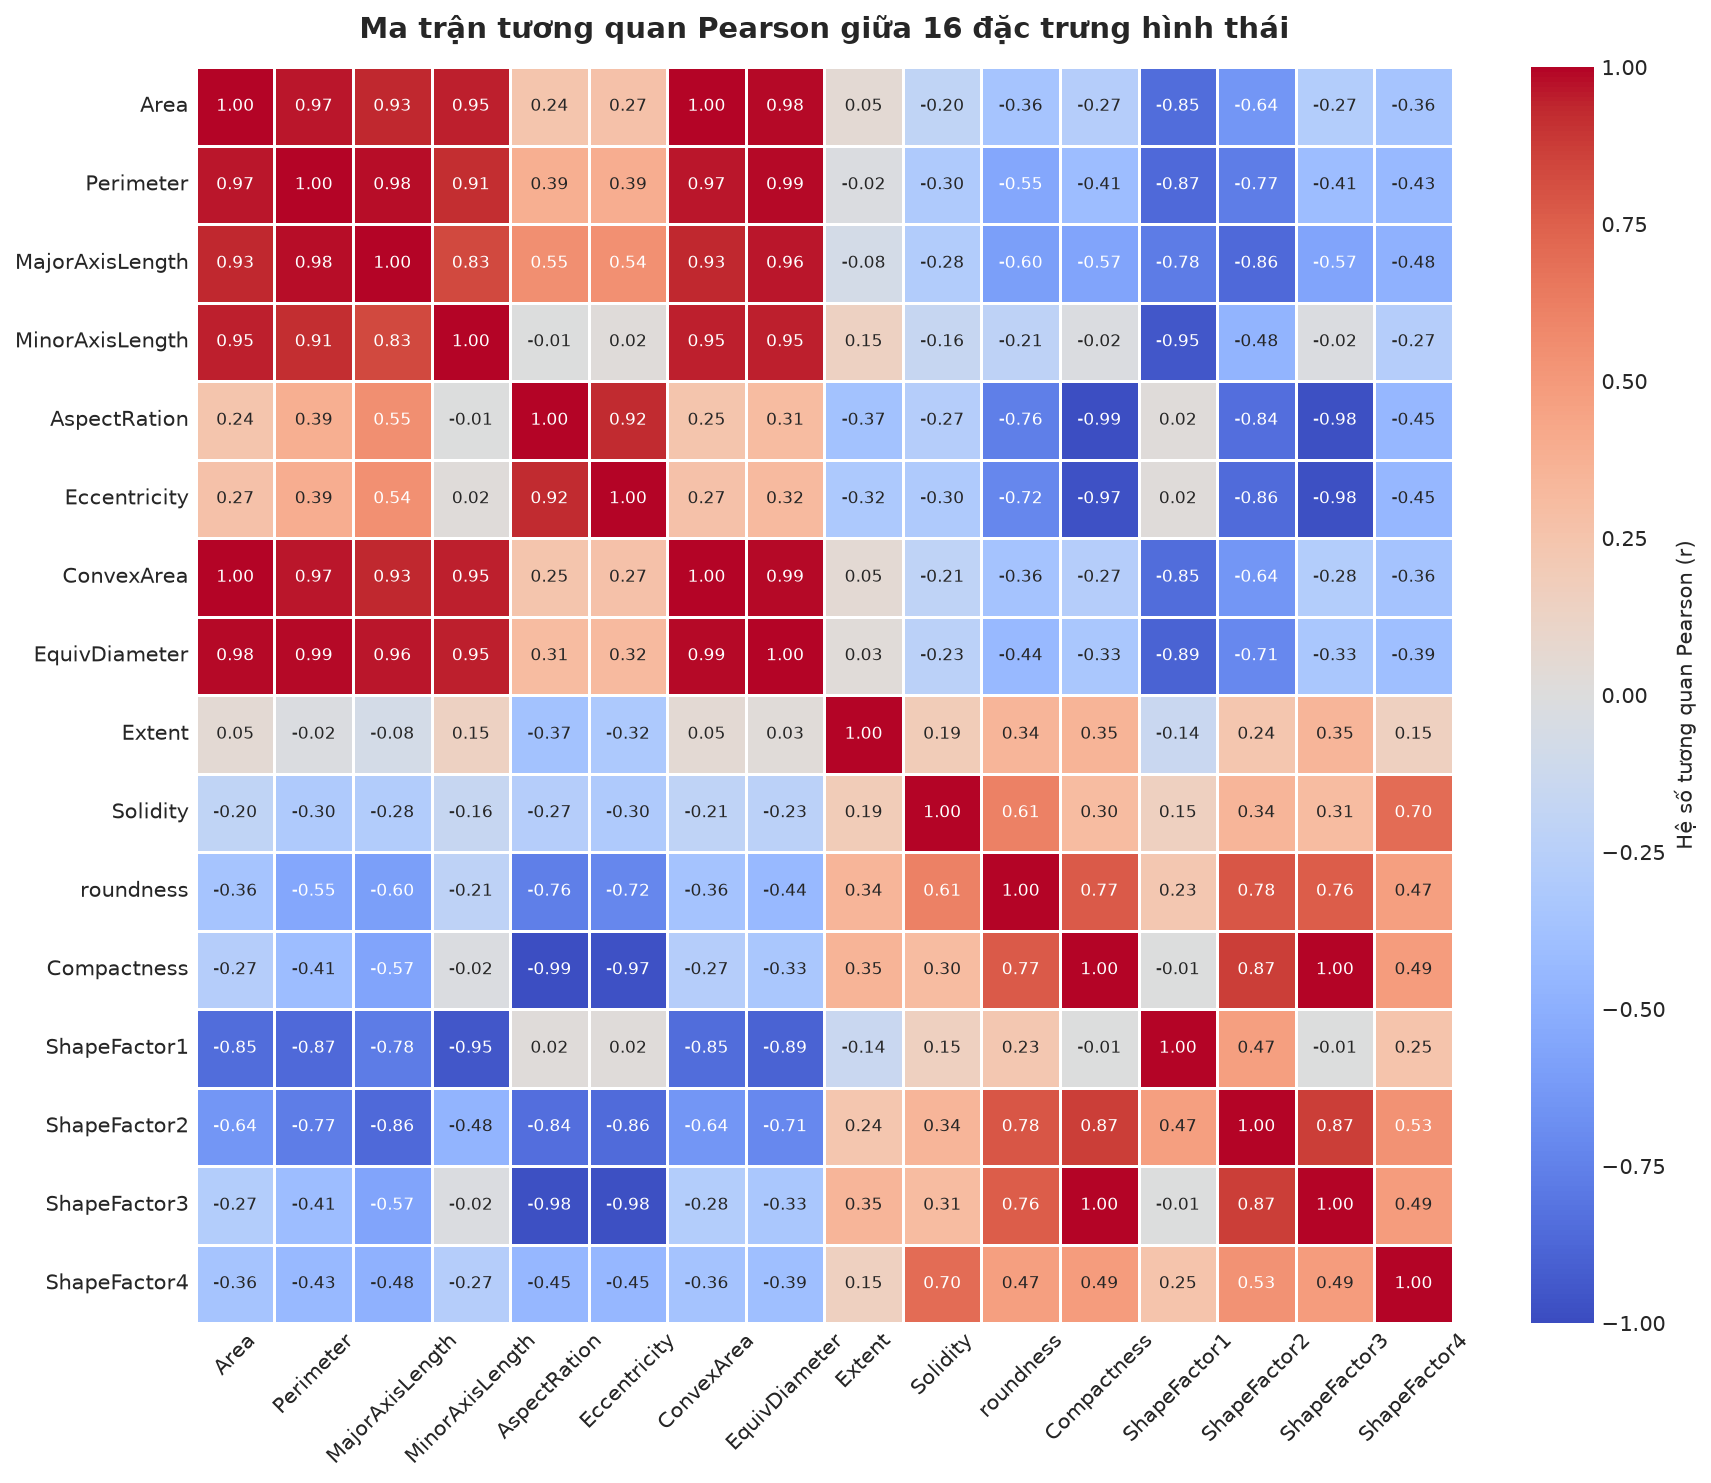

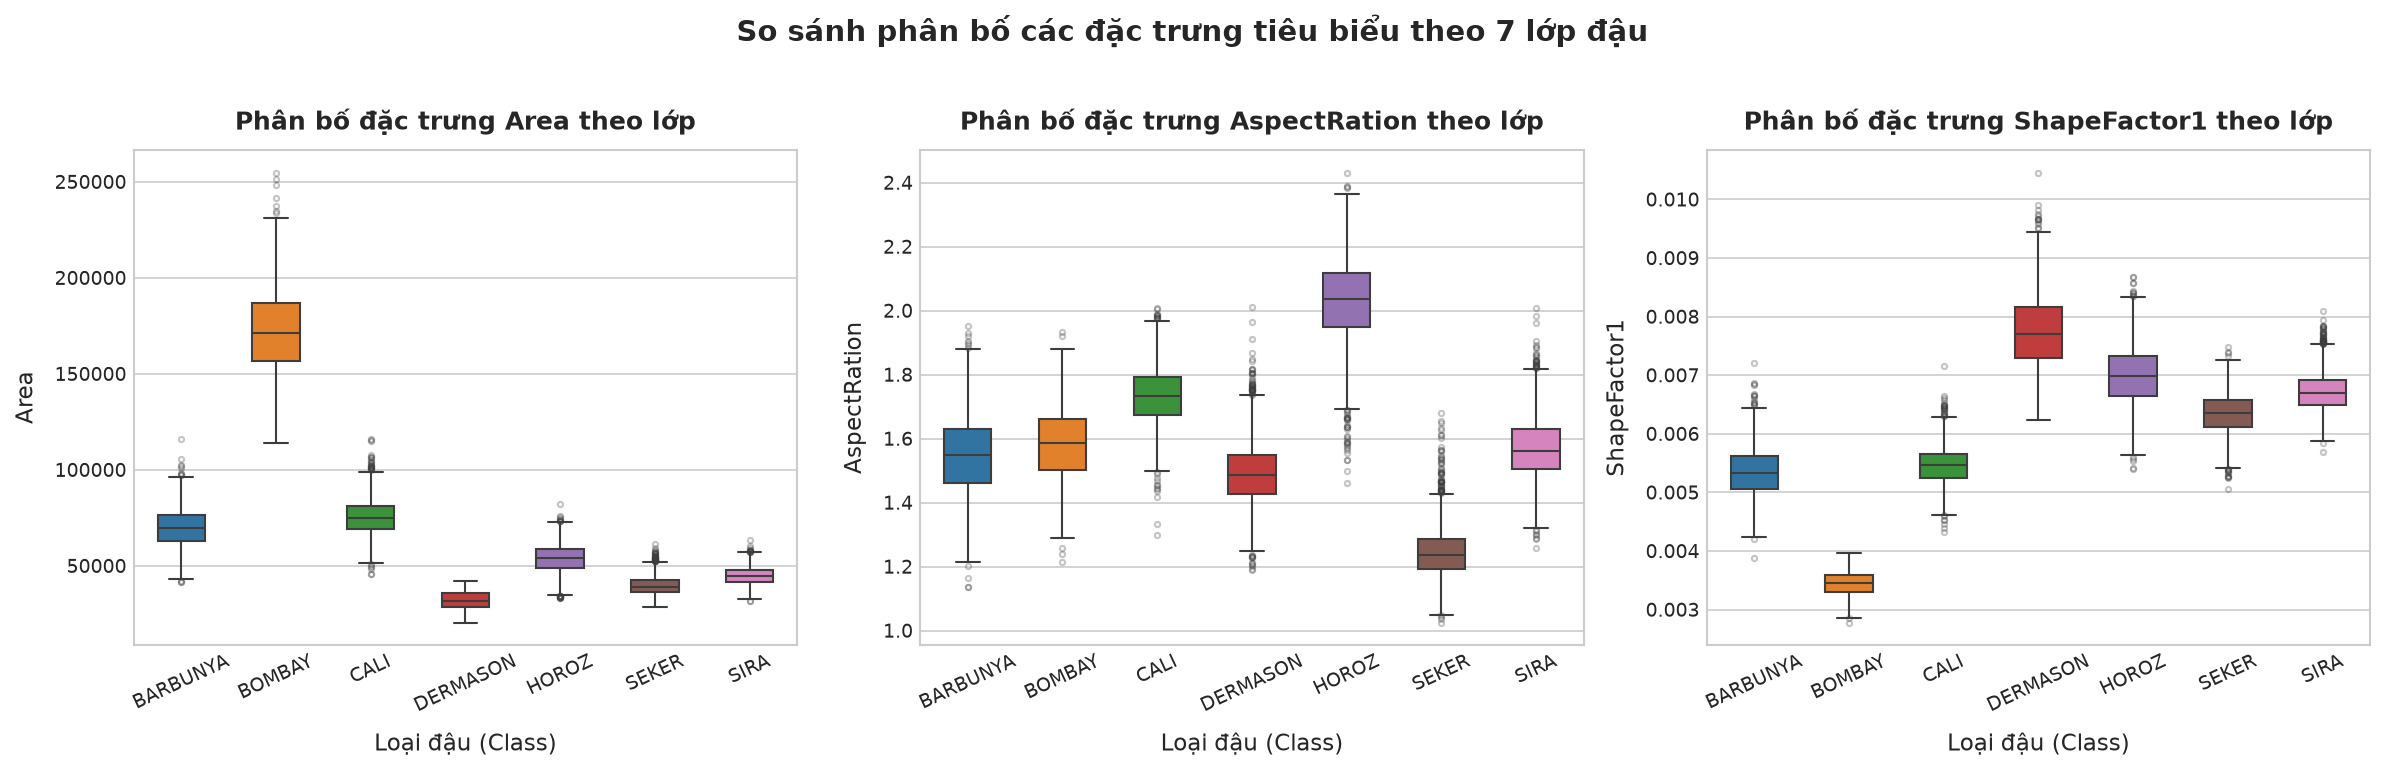

In [6]:
def analyze_multivariate_eda(
    df: pd.DataFrame, output_dir: str = OUTPUT_DIR
) -> list[tuple[str, str, float]]:
    """Phân tích đa cộng tuyến |r| > 0.9, vẽ Biểu đồ 04 (Heatmap) & 05 (Boxplot theo lớp)."""
    corr = df[ALL_FEATURES].corr()
    high_corr_pairs = []
    for i in range(len(ALL_FEATURES)):
        for j in range(i + 1, len(ALL_FEATURES)):
            f1, f2 = ALL_FEATURES[i], ALL_FEATURES[j]
            r_val = float(corr.loc[f1, f2])
            if abs(r_val) > 0.9:
                high_corr_pairs.append((f1, f2, r_val))

    high_corr_pairs.sort(key=lambda item: abs(item[2]), reverse=True)

    print(f"DANH SÁCH CÁC CẶP ĐẶC TRƯNG TƯƠNG QUAN CAO (|r| > 0.9): {len(high_corr_pairs)} cặp")
    header = (
        f"{'STT':<4} | {'Đặc trưng 1':<16} - {'Đặc trưng 2':<16} | "
        f"{'Hệ số r':>9} | {'Mức độ tương quan'}"
    )
    print("-" * len(header))
    print(header)
    print("-" * len(header))
    for idx, (f1, f2, r_val) in enumerate(high_corr_pairs, 1):
        rel = "Đồng biến rất mạnh" if r_val > 0 else "Nghịch biến rất mạnh"
        print(f"{idx:<4} | {f1:<16} - {f2:<16} | {r_val:>9.4f} | {rel}")
    print("-" * len(header))

    # Biểu đồ 04: Heatmap tương quan Pearson
    fig1, ax1 = plt.subplots(figsize=(12, 10))
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        ax=ax1,
        annot_kws={"size": 8},
        cbar_kws={"label": "Hệ số tương quan Pearson (r)"},
        linewidths=0.5,
        linecolor="white",
    )
    ax1.set_title(
        "Ma trận tương quan Pearson giữa 16 đặc trưng hình thái",
        fontsize=14,
        fontweight="bold",
        pad=14,
    )
    ax1.tick_params(axis="x", rotation=45, labelsize=10)
    ax1.tick_params(axis="y", rotation=0, labelsize=10)
    plt.tight_layout()
    out_corr = os.path.join(output_dir, "04_ma_tran_tuong_quan.png")
    fig1.savefig(out_corr, dpi=300, bbox_inches="tight")
    print(f"\n- Đã lưu biểu đồ: '{out_corr}' (DPI 300)")
    plt.show()
    plt.close(fig1)

    # Biểu đồ 05: Boxplot 3 đặc trưng tiêu biểu theo 7 lớp
    selected_features = ["Area", "AspectRation", "ShapeFactor1"]
    fig2, axes2 = plt.subplots(1, 3, figsize=(16, 5))

    for idx, feature in enumerate(selected_features):
        ax = axes2[idx]
        sns.boxplot(
            x=CLASS_COLUMN,
            y=feature,
            data=df,
            order=CLASS_NAMES,
            palette=CLASS_COLOR_MAP,
            ax=ax,
            width=0.5,
            fliersize=2.5,
            flierprops=dict(marker="o", alpha=0.3),
        )
        ax.set_title(
            f"Phân bố đặc trưng {feature} theo lớp",
            fontsize=12,
            fontweight="bold",
            pad=10,
        )
        ax.set_xlabel("Loại đậu (Class)", fontsize=11, labelpad=8)
        ax.set_ylabel(feature, fontsize=11, labelpad=8)
        ax.tick_params(axis="x", rotation=25, labelsize=9)
        ax.tick_params(axis="y", labelsize=9)

    fig2.suptitle(
        "So sánh phân bố các đặc trưng tiêu biểu theo 7 lớp đậu",
        fontsize=14,
        fontweight="bold",
        y=1.02,
    )
    plt.tight_layout()
    out_cls = os.path.join(output_dir, "05_boxplot_theo_lop.png")
    fig2.savefig(out_cls, dpi=300, bbox_inches="tight")
    print(f"- Đã lưu biểu đồ: '{out_cls}' (DPI 300)")
    plt.show()
    plt.close(fig2)

    return high_corr_pairs


high_corr_pairs = analyze_multivariate_eda(df_clean)

### 3.4. Nhận xét tổng quan kết quả EDA
1. **Về hiện tượng đa cộng tuyến (Multicollinearity):**
   - Phát hiện **21 cặp đặc trưng** có hệ số tương quan $|r| > 0.9$. Trong đó, nhóm Kích thước chứa đa cộng tuyến cực đại như `Area` – `ConvexArea` ($r = 0.9999$) và `Perimeter` – `EquivDiameter` ($r = 0.9915$). Ở nhóm Hình dạng, `Compactness` tương quan gần như tuyệt đối với `ShapeFactor3` ($r = 0.9987$).
   - **Hệ quả thuật toán dự kiến:** `GaussianNB` dựa trên giả định các đặc trưng độc lập có điều kiện sẽ bị suy giảm hiệu năng khi có nhiều biến dư thừa đồng tuyến tính trong nhóm Kích thước, trong khi `DecisionTreeClassifier` ít bị ảnh hưởng hơn vì tại mỗi nút chỉ chọn một đặc trưng chia tách tối ưu nhất.
2. **Về khả năng phân tách 7 lớp đậu:**
   - **Nhóm Kích thước (`Area`):** Tách biệt hoàn toàn giống hạt khổng lồ `BOMBAY` khỏi 6 giống còn lại.
   - **Nhóm Hình dạng (`AspectRation`, `ShapeFactor1`):** Tách rõ giống hạt thon dài (`HOROZ`, `CALI`) khỏi giống hạt tròn (`SEKER`, `DERMASON`) và phân biệt các giống có kích thước gần bằng nhau như `DERMASON` và `SIRA`.

## Phần 4: Học có giám sát & Trả lời RQ1

### 4.1. Thiết lập thực nghiệm phân loại & Chống rò rỉ dữ liệu
- **Phân chia dữ liệu:** Chia tập dữ liệu sạch ($13.543$ mẫu) thành **80% Train ($10.834$ mẫu)** và **20% Test ($2.709$ mẫu)** với `stratify=y` và `random_state=42` nhằm bảo toàn chính xác tỷ lệ 7 giống đậu trên cả hai tập.
- **Quy tắc dữ liệu thô:** Tuyệt đối **không áp dụng `StandardScaler`** cho `GaussianNB` và `DecisionTreeClassifier`.
- **Chiến lược chọn mô hình:** Đánh giá 6 tổ hợp (2 thuật toán $\times$ 3 bộ đặc trưng) bằng **5-fold Stratified Cross-Validation** hoàn toàn trên tập Train. Mô hình có điểm **F1-macro CV trung bình** cao nhất được chọn làm mô hình tối ưu trước khi kiểm chứng duy nhất một lần trên tập Test.

In [ ]:
print("=" * 70)
print("BƯỚC 6 & 7: CHIA TẬP 80/20 STRATIFY & HUẤN LUYỆN 6 TỔ HỢP")
print("=" * 70)

X = df_clean[ALL_FEATURES]
y = df_clean[CLASS_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"- Tập huấn luyện (Train): {X_train.shape[0]:,} mẫu (80.00%), {X_train.shape[1]} đặc trưng.")
print(f"- Tập kiểm tra   (Test) : {X_test.shape[0]:,} mẫu (20.00%), {X_test.shape[1]} đặc trưng.")

print("\nSo sánh tỷ lệ phân bố 7 lớp giữa tập Train và Test:")
header = (
    f"{'Lớp (Class)':<12} | {'Train (Số lượng)':>16} | {'Train (%)':>10} | "
    f"{'Test (Số lượng)':>15} | {'Test (%)':>9}"
)
print("-" * len(header))
print(header)
print("-" * len(header))
train_cnts, train_rats = y_train.value_counts(), y_train.value_counts(normalize=True) * 100
test_cnts, test_rats = y_test.value_counts(), y_test.value_counts(normalize=True) * 100
for cls in CLASS_NAMES:
    print(
        f"{cls:<12} | {train_cnts[cls]:>16} | {train_rats[cls]:>9.2f}% | "
        f"{test_cnts[cls]:>15} | {test_rats[cls]:>8.2f}%"
    )
print("-" * len(header))

# Huấn luyện 6 tổ hợp trên dữ liệu thô tập Train
FEATURE_SETS = {
    "Toàn bộ (16 đặc trưng)": ALL_FEATURES,
    "Kích thước (8 đặc trưng)": SIZE_FEATURES,
    "Hình dạng (8 đặc trưng)": SHAPE_FEATURES,
}

ALGORITHMS = {
    "GaussianNB": lambda: GaussianNB(),
    "Decision Tree": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
}

trained_models = {}
comb_idx = 1
print("\nTiến độ huấn luyện 6 tổ hợp mô hình (dữ liệu thô):")
for algo_name, algo_fn in ALGORITHMS.items():
    for set_name, feat_list in FEATURE_SETS.items():
        model = algo_fn()
        X_tr_sub = X_train[feat_list]
        model.fit(X_tr_sub, y_train)
        key = f"{algo_name} - {set_name}"
        trained_models[key] = {
            "model": model,
            "algorithm": algo_name,
            "feature_set_name": set_name,
            "features": feat_list,
        }
        print(
            f"  [{comb_idx}/6] {algo_name:<13} trên '{set_name}' "
            f"({X_tr_sub.shape[0]:,} mẫu, {len(feat_list)} đặc trưng) -> Hoàn thành!"
        )
        comb_idx += 1

BƯỚC 6 & 7: CHIA TẬP 80/20 STRATIFY & HUẤN LUYỆN 6 TỔ HỢP (TASK T7)
- Tập huấn luyện (Train): 10,834 mẫu (80.00%), 16 đặc trưng.
- Tập kiểm tra   (Test) : 2,709 mẫu (20.00%), 16 đặc trưng.

So sánh tỷ lệ phân bố 7 lớp giữa tập Train và Test:
--------------------------------------------------------------------------
Lớp (Class)  | Train (Số lượng) |  Train (%) | Test (Số lượng) |  Test (%)
--------------------------------------------------------------------------
BARBUNYA     |             1057 |      9.76% |             265 |     9.78%
BOMBAY       |              418 |      3.86% |             104 |     3.84%
CALI         |             1304 |     12.04% |             326 |    12.03%
DERMASON     |             2837 |     26.19% |             709 |    26.17%
HOROZ        |             1488 |     13.73% |             372 |    13.73%
SEKER        |             1621 |     14.96% |             406 |    14.99%
SIRA         |             2109 |     19.47% |             527 |    19.45%
--------

In [ ]:
print("=" * 70)
print("BƯỚC 8: ĐÁNH GIÁ 5-FOLD STRATIFIED CV TRÊN TẬP TRAIN")
print("=" * 70)

skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_records = []
best_f1 = -1.0
best_model_info = {}

for algo_name, algo_fn in ALGORITHMS.items():
    for set_name, feat_list in FEATURE_SETS.items():
        cv_out = cross_validate(
            algo_fn(),
            X_train[feat_list],
            y_train,
            cv=skf,
            scoring=["accuracy", "f1_macro"],
        )
        f1_m, f1_s = float(cv_out["test_f1_macro"].mean()), float(cv_out["test_f1_macro"].std())
        acc_m, acc_s = float(cv_out["test_accuracy"].mean()), float(cv_out["test_accuracy"].std())

        cv_records.append(
            {
                "Thuật toán": algo_name,
                "Bộ đặc trưng": set_name,
                "F1-macro (Mean)": f1_m,
                "F1-macro (Std)": f1_s,
                "Accuracy (Mean)": acc_m,
                "Accuracy (Std)": acc_s,
                "features": feat_list,
            }
        )

        if f1_m > best_f1:
            best_f1 = f1_m
            best_model_info = {
                "algorithm": algo_name,
                "feature_set_name": set_name,
                "features": feat_list,
                "f1_mean": f1_m,
                "f1_std": f1_s,
                "acc_mean": acc_m,
                "acc_std": acc_s,
            }

cv_df = pd.DataFrame(cv_records)
header = (
    f"{'Thuật toán':<14} | {'Bộ đặc trưng':<24} | "
    f"{'F1-macro CV (Mean ± Std)':>26} | {'Accuracy CV (Mean ± Std)':>26}"
)
print("-" * len(header))
print(header)
print("-" * len(header))
for _, row in cv_df.iterrows():
    f1_str = f"{row['F1-macro (Mean)']:.4f} ± {row['F1-macro (Std)']:.4f}"
    acc_str = f"{row['Accuracy (Mean)']:.4f} ± {row['Accuracy (Std)']:.4f}"
    print(f"{row['Thuật toán']:<14} | {row['Bộ đặc trưng']:<24} | {f1_str:>26} | {acc_str:>26}")
print("-" * len(header))

print(
    f"\n=> MÔ HÌNH TỐI ƯU ĐƯỢC CHỌN: {best_model_info['algorithm']} - "
    f"{best_model_info['feature_set_name']}\n"
    f"   - F1-macro CV (5-fold): {best_model_info['f1_mean']:.4f} ± {best_model_info['f1_std']:.4f}\n"
    f"   - Accuracy CV (5-fold): {best_model_info['acc_mean']:.4f} ± {best_model_info['acc_std']:.4f}"
)

BƯỚC 8: ĐÁNH GIÁ 5-FOLD STRATIFIED CV TRÊN TẬP TRAIN (TASK T8)
---------------------------------------------------------------------------------------------------
Thuật toán     | Bộ đặc trưng             |   F1-macro CV (Mean ± Std) |   Accuracy CV (Mean ± Std)
---------------------------------------------------------------------------------------------------
GaussianNB     | Toàn bộ (16 đặc trưng)   |            0.7632 ± 0.0085 |            0.7620 ± 0.0073
GaussianNB     | Kích thước (8 đặc trưng) |            0.7625 ± 0.0080 |            0.7612 ± 0.0068
GaussianNB     | Hình dạng (8 đặc trưng)  |            0.9062 ± 0.0067 |            0.8916 ± 0.0082
Decision Tree  | Toàn bộ (16 đặc trưng)   |            0.9107 ± 0.0046 |            0.8960 ± 0.0058
Decision Tree  | Kích thước (8 đặc trưng) |            0.8878 ± 0.0056 |            0.8756 ± 0.0055
Decision Tree  | Hình dạng (8 đặc trưng)  |            0.9128 ± 0.0072 |            0.8984 ± 0.0072
-------------------------------------

BƯỚC 9 & 10: ĐÁNH GIÁ TẬP KIỂM TRA & TRỰC QUAN HÓA RQ1 (TASKS T9, T10)

1. KẾT QUẢ MÔ HÌNH TỐT NHẤT TRÊN TEST SET (2,709 MẪU): Decision Tree - Hình dạng (8 đặc trưng)
   - Accuracy trên Test set : 0.8963
   - F1-macro trên Test set : 0.9099

Báo cáo phân loại chi tiết (Classification Report):
              precision    recall  f1-score   support

    BARBUNYA     0.9023    0.8717    0.8868       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.8820    0.9172    0.8992       326
    DERMASON     0.9046    0.8956    0.9001       709
       HOROZ     0.9270    0.9220    0.9245       372
       SEKER     0.9293    0.9384    0.9338       406
        SIRA     0.8239    0.8254    0.8246       527

    accuracy                         0.8963      2709
   macro avg     0.9099    0.9101    0.9099      2709
weighted avg     0.8964    0.8963    0.8962      2709

=> Cặp lớp nhầm lẫn nhiều nhất: DERMASON <-> SIRA (116 mẫu 2 chiều: DERMASON->SIRA=65, SIRA->DERMASON=51).

-

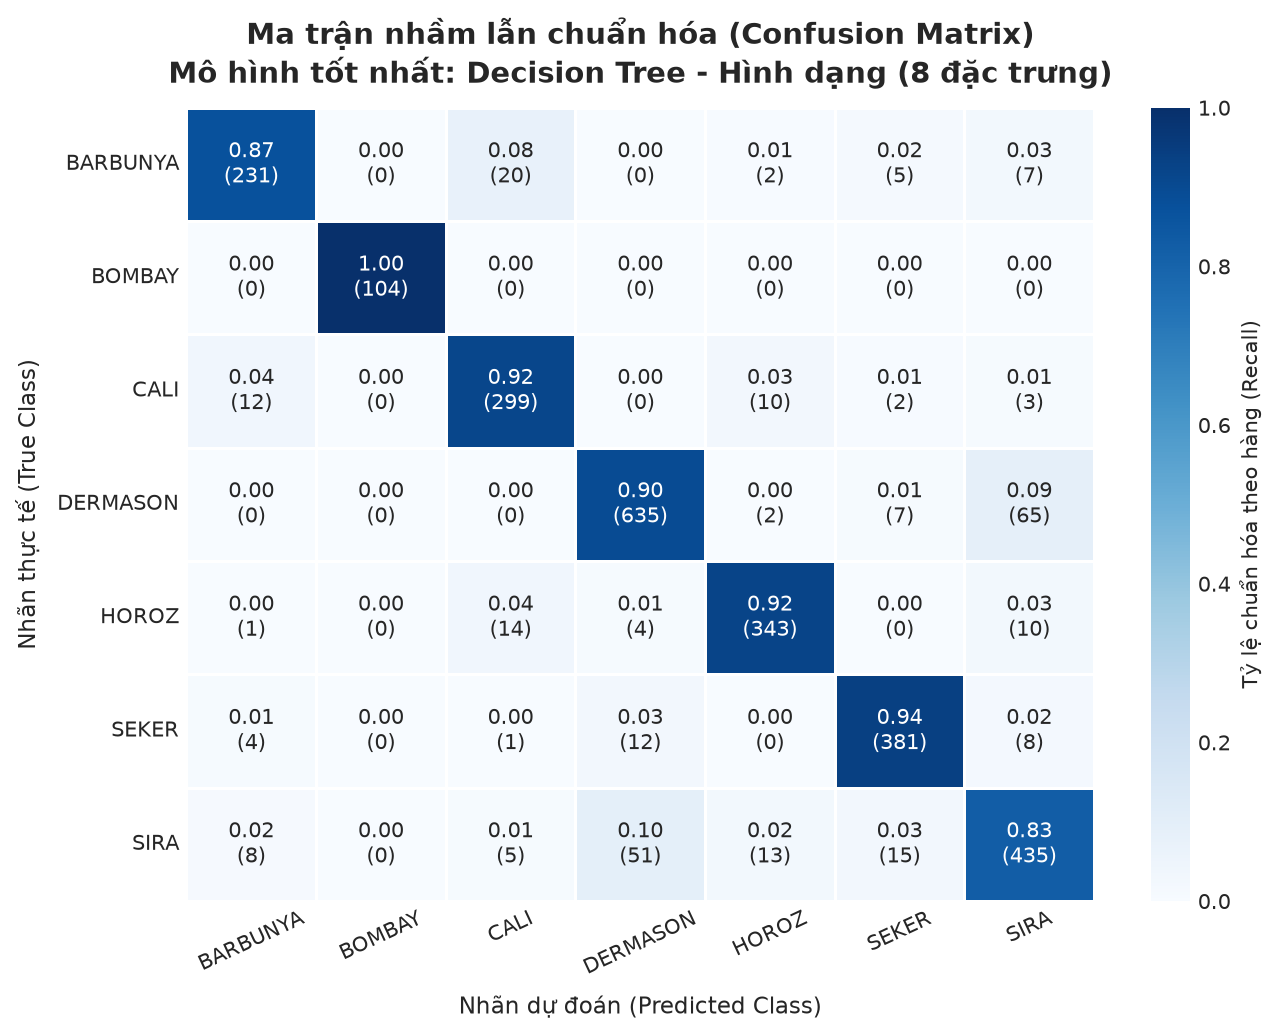

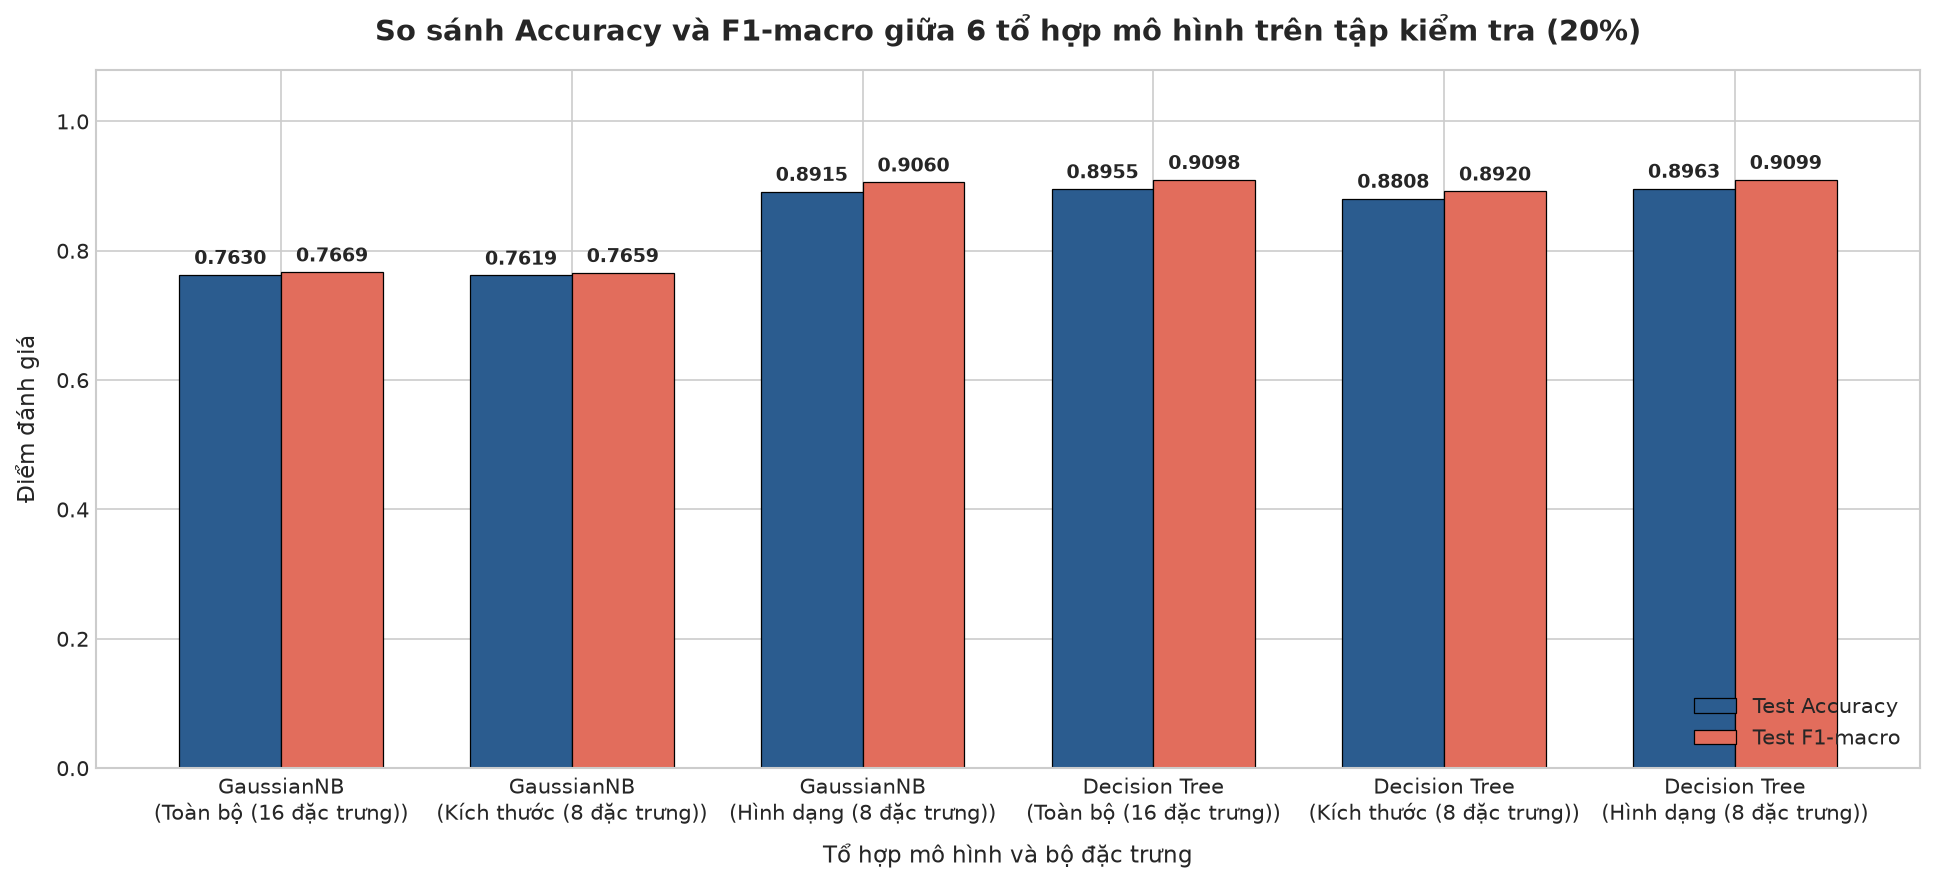

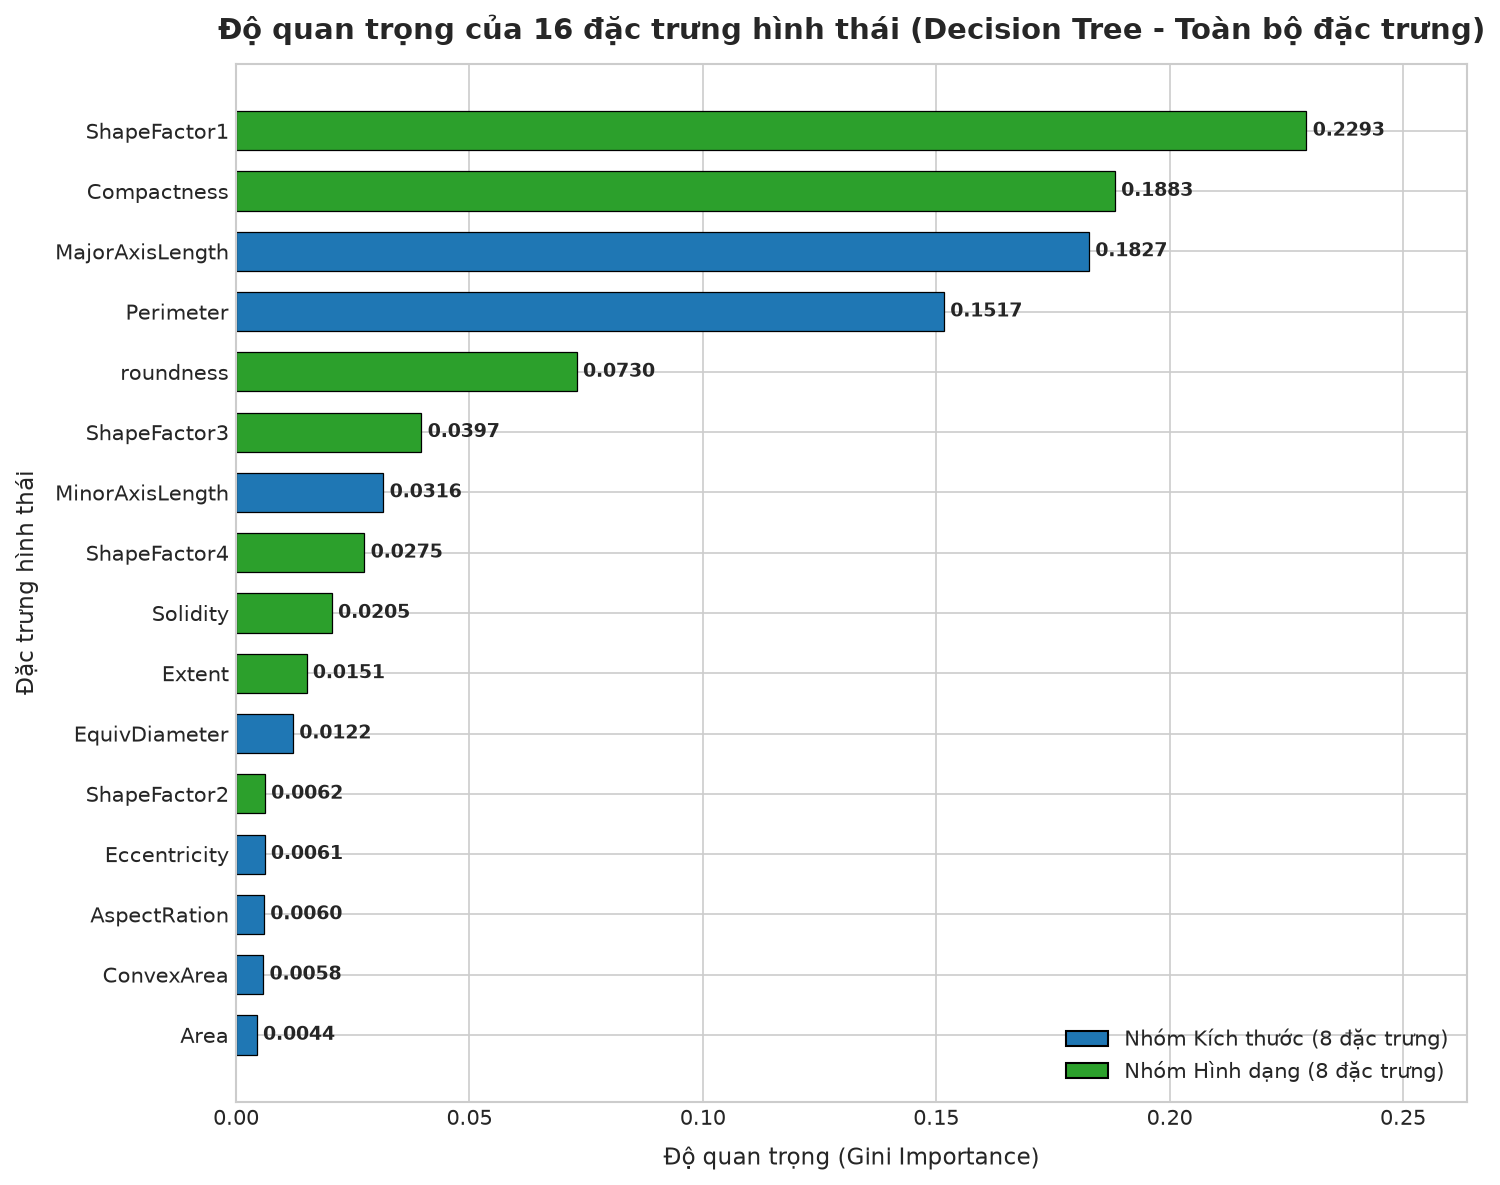

In [ ]:
print("=" * 70)
print("BƯỚC 9 & 10: ĐÁNH GIÁ TẬP KIỂM TRA & TRỰC QUAN HÓA RQ1")
print("=" * 70)

# 1. Đánh giá cả 6 tổ hợp trên Test set để lập bảng tổng kết đầy đủ
eval_records = []
for key, item in trained_models.items():
    preds = item["model"].predict(X_test[item["features"]])
    cv_row = cv_df[
        (cv_df["Thuật toán"] == item["algorithm"])
        & (cv_df["Bộ đặc trưng"] == item["feature_set_name"])
    ].iloc[0]
    eval_records.append(
        {
            "Thuật toán": item["algorithm"],
            "Bộ đặc trưng": item["feature_set_name"],
            "F1_CV_Mean": cv_row["F1-macro (Mean)"],
            "F1_CV_Std": cv_row["F1-macro (Std)"],
            "Acc_CV_Mean": cv_row["Accuracy (Mean)"],
            "Acc_CV_Std": cv_row["Accuracy (Std)"],
            "Acc_Test": float(accuracy_score(y_test, preds)),
            "F1_Test": float(f1_score(y_test, preds, average="macro")),
        }
    )
summary_df = pd.DataFrame(eval_records)

# 2. Đánh giá chi tiết mô hình tốt nhất
best_key = f"{best_model_info['algorithm']} - {best_model_info['feature_set_name']}"
best_model = trained_models[best_key]["model"]
best_features = best_model_info["features"]
y_pred_best = best_model.predict(X_test[best_features])

acc_test_best = accuracy_score(y_test, y_pred_best)
f1_test_best = f1_score(y_test, y_pred_best, average="macro")

print(f"\n1. KẾT QUẢ MÔ HÌNH TỐT NHẤT TRÊN TEST SET ({len(X_test):,} MẪU): {best_key}")
print(f"   - Accuracy trên Test set : {acc_test_best:.4f}")
print(f"   - F1-macro trên Test set : {f1_test_best:.4f}")
print("\nBáo cáo phân loại chi tiết (Classification Report):")
print(classification_report(y_test, y_pred_best, target_names=CLASS_NAMES, digits=4))

# Tìm cặp lớp nhầm lẫn nhiều nhất
cm = confusion_matrix(y_test, y_pred_best, labels=CLASS_NAMES)
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
pair_err = {}
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        if i != j:
            pair = tuple(sorted([CLASS_NAMES[i], CLASS_NAMES[j]]))
            pair_err[pair] = pair_err.get(pair, 0) + int(cm[i, j])
top_pair, top_cnt = max(pair_err.items(), key=lambda x: x[1])
idx_a, idx_b = CLASS_NAMES.index(top_pair[0]), CLASS_NAMES.index(top_pair[1])
print(
    f"=> Cặp lớp nhầm lẫn nhiều nhất: {top_pair[0]} <-> {top_pair[1]} "
    f"({top_cnt} mẫu 2 chiều: {top_pair[0]}->{top_pair[1]}={cm[idx_a, idx_b]}, "
    f"{top_pair[1]}->{top_pair[0]}={cm[idx_b, idx_a]})."
)

# 3. Biểu đồ 06: Confusion Matrix chuẩn hóa theo hàng kèm số lượng mẫu đếm thực tế
annot_matrix = np.empty_like(cm, dtype=object)
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        annot_matrix[i, j] = f"{cm_norm[i, j]:.2f}\n({cm[i, j]})"

fig_cm, ax_cm = plt.subplots(figsize=(9, 7))
sns.heatmap(
    cm_norm,
    annot=annot_matrix,
    fmt="",
    cmap="Blues",
    vmin=0.0,
    vmax=1.0,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ax=ax_cm,
    cbar_kws={"label": "Tỷ lệ chuẩn hóa theo hàng (Recall)"},
    linewidths=0.5,
    linecolor="white",
)
ax_cm.set_title(
    f"Ma trận nhầm lẫn chuẩn hóa (Confusion Matrix)\nMô hình tốt nhất: {best_key}",
    fontsize=14,
    fontweight="bold",
    pad=12,
)
ax_cm.set_xlabel("Nhãn dự đoán (Predicted Class)", fontsize=11, labelpad=8)
ax_cm.set_ylabel("Nhãn thực tế (True Class)", fontsize=11, labelpad=8)
ax_cm.tick_params(axis="x", rotation=25, labelsize=10)
ax_cm.tick_params(axis="y", rotation=0, labelsize=10)
plt.tight_layout()
out_cm = os.path.join(OUTPUT_DIR, "06_confusion_matrix.png")
fig_cm.savefig(out_cm, dpi=300, bbox_inches="tight")
print(f"\n- Đã lưu biểu đồ: '{out_cm}' (DPI 300)")
plt.show()
plt.close(fig_cm)

# 4. Biểu đồ 07: Grouped Bar Chart so sánh 6 tổ hợp (F1-macro CV & Accuracy CV)
fig_cmp, ax_cmp = plt.subplots(figsize=(13, 6))
labels_cmp = [
    f"{r['Thuật toán']}\n({r['Bộ đặc trưng']})" for _, r in summary_df.iterrows()
]
x_pos = np.arange(len(labels_cmp))
bar_w = 0.35

rects1 = ax_cmp.bar(
    x_pos - bar_w / 2,
    summary_df["Acc_Test"],
    bar_w,
    label="Test Accuracy",
    color="#2b5c8f",
    edgecolor="black",
    linewidth=0.6,
)
rects2 = ax_cmp.bar(
    x_pos + bar_w / 2,
    summary_df["F1_Test"],
    bar_w,
    label="Test F1-macro",
    color="#e26d5c",
    edgecolor="black",
    linewidth=0.6,
)
ax_cmp.bar_label(rects1, fmt="%.4f", padding=3, fontsize=9, fontweight="bold")
ax_cmp.bar_label(rects2, fmt="%.4f", padding=3, fontsize=9, fontweight="bold")
ax_cmp.set_title(
    "So sánh Accuracy và F1-macro giữa 6 tổ hợp mô hình trên tập kiểm tra (20%)",
    fontsize=14,
    fontweight="bold",
    pad=14,
)
ax_cmp.set_xlabel("Tổ hợp mô hình và bộ đặc trưng", fontsize=11, labelpad=8)
ax_cmp.set_ylabel("Điểm đánh giá", fontsize=11, labelpad=8)
ax_cmp.set_xticks(x_pos)
ax_cmp.set_xticklabels(labels_cmp, fontsize=10)
ax_cmp.tick_params(axis="y", labelsize=10)
ax_cmp.set_ylim(0, 1.08)
ax_cmp.legend(loc="lower right", fontsize=10)
plt.tight_layout()
out_cmp = os.path.join(OUTPUT_DIR, "07_so_sanh_mo_hinh.png")
fig_cmp.savefig(out_cmp, dpi=300, bbox_inches="tight")
print(f"- Đã lưu biểu đồ: '{out_cmp}' (DPI 300)")
plt.show()
plt.close(fig_cmp)

# 5. Biểu đồ 08: feature_importances_ Decision Tree trên toàn bộ 16 đặc trưng
dt_all_model = trained_models["Decision Tree - Toàn bộ (16 đặc trưng)"]["model"]
imp_all = pd.Series(dt_all_model.feature_importances_, index=ALL_FEATURES)
imp_asc = imp_all.sort_values(ascending=True)

size_imp_sum = float(imp_all[SIZE_FEATURES].sum())
shape_imp_sum = float(imp_all[SHAPE_FEATURES].sum())
print(
    f"\n2. TỶ TRỌNG ĐÓNG GÓP (DECISION TREE 16 ĐẶC TRƯNG):\n"
    f"   - Nhóm Hình dạng  : {shape_imp_sum:.4f} ({shape_imp_sum * 100:.2f}%)\n"
    f"   - Nhóm Kích thước : {size_imp_sum:.4f} ({size_imp_sum * 100:.2f}%)"
)

colors_imp = ["#1f77b4" if f in SIZE_FEATURES else "#2ca02c" for f in imp_asc.index]
fig_imp, ax_imp = plt.subplots(figsize=(10, 8))
bars_imp = ax_imp.barh(
    imp_asc.index,
    imp_asc.values,
    color=colors_imp,
    edgecolor="black",
    linewidth=0.6,
    height=0.65,
)
ax_imp.bar_label(bars_imp, fmt="%.4f", padding=3, fontsize=9, fontweight="bold")
ax_imp.set_title(
    "Độ quan trọng của 16 đặc trưng hình thái (Decision Tree - Toàn bộ đặc trưng)",
    fontsize=14,
    fontweight="bold",
    pad=12,
)
ax_imp.set_xlabel("Độ quan trọng (Gini Importance)", fontsize=11, labelpad=8)
ax_imp.set_ylabel("Đặc trưng hình thái", fontsize=11, labelpad=8)
ax_imp.tick_params(axis="both", labelsize=10)
ax_imp.set_xlim(0, max(imp_asc.values) * 1.15)
legend_imp = [
    Patch(facecolor="#1f77b4", edgecolor="black", label="Nhóm Kích thước (8 đặc trưng)"),
    Patch(facecolor="#2ca02c", edgecolor="black", label="Nhóm Hình dạng (8 đặc trưng)"),
]
ax_imp.legend(handles=legend_imp, loc="lower right", fontsize=10)
plt.tight_layout()
out_imp = os.path.join(OUTPUT_DIR, "08_feature_importances.png")
fig_imp.savefig(out_imp, dpi=300, bbox_inches="tight")
print(f"- Đã lưu biểu đồ: '{out_imp}' (DPI 300)")
plt.show()
plt.close(fig_imp)

### 4.2. Kết luận định lượng giải quyết RQ1

**Câu trả lời trực diện:** **Nhóm đặc trưng Hình dạng (*Shape Features*)** giúp xác định loại đậu chính xác hơn rõ rệt so với nhóm Kích thước.

**Các bằng chứng thực nghiệm then chốt:**
1. **Hiệu năng vượt trội trên cả hai thuật toán (5-fold Stratified CV trên tập Train):**
   - Với `GaussianNB`: F1-macro CV tăng vọt từ **`0.7625`** (Kích thước) lên **`0.9062`** (Hình dạng), tương ứng mức tăng **+14,37%**. Nguyên nhân là nhóm Kích thước chịu ảnh hưởng nặng nề của đa cộng tuyến ($r = 0.9999$), làm vi phạm giả định độc lập có điều kiện của Naive Bayes.
   - Với `DecisionTreeClassifier`: F1-macro CV của nhóm Hình dạng đạt **`0.9128 ± 0.0072`** (vượt nhóm Kích thước **`0.8878 ± 0.0056`**, tăng **+2,50%**; đồng thời nhỉnh hơn cả bộ Toàn bộ 16 đặc trưng **`0.9107 ± 0.0046`**).
2. **Áp đảo về tỷ trọng Gini Importance (`feature_importances_`):**
   - Trong cây quyết định đầy đủ 16 đặc trưng, **Nhóm Hình dạng chiếm `0.5995` (59,95%)** tổng trọng số đóng góp, gấp **1,50 lần** so với **Nhóm Kích thước (`0.4005` / 40,05%)**.
   - Hai đặc trưng có độ quan trọng cao nhất toàn bộ tập dữ liệu đều thuộc nhóm Hình dạng: `ShapeFactor1` (`0.2293` / 22,93%) và `Compactness` (`0.1883` / 18,83%).
3. **Đánh giá khách quan trên Tập kiểm tra (Test set = 2.709 mẫu):**
   - Mô hình tốt nhất (`Decision Tree - Hình dạng`) đạt **Accuracy = `0.8963` (89,63%)** và **F1-macro = `0.9099` (90,99%)**; phân loại chính xác tuyệt đối `1.0000` cho giống `BOMBAY`, trong khi vùng chồng lấn lớn nhất là cặp hạt nhỏ `DERMASON` $\leftrightarrow$ `SIRA` (116 mẫu nhầm 2 chiều).
4. **Ý nghĩa nông học:** Kích thước tuyệt đối (`Area`, `Perimeter`) dễ bị biến động bởi môi trường gieo trồng (độ ẩm, lượng mưa, thổ nhưỡng), trong khi các tỷ lệ hình thái không thứ nguyên là đặc trưng di truyền ổn định của từng giống đậu.

## Phần 5: Học không giám sát & Trả lời RQ2

### 5.1. Thiết lập bài toán phân cụm K-Means & Chuẩn hóa `StandardScaler`
- **Tách nhãn tuyệt đối:** Cột mục tiêu `Class` hoàn toàn không được đưa vào mô hình K-Means; nó chỉ được giữ lại để đối chiếu hậu kiểm ở bước đánh giá độ khớp (`Crosstab` và `ARI`).
- **Chuẩn hóa dữ liệu (`StandardScaler`):** Vì các đặc trưng có đơn vị chênh lệch hàng triệu lần (ví dụ `Area` đạt hàng chục nghìn pixel² trong khi `ShapeFactor2` ở mức `0.0017`), việc chuẩn hóa về $\mu = 0, \sigma = 1$ là bắt buộc để khoảng cách Euclidean trong K-Means và phương sai trong PCA không bị chi phối hoàn toàn bởi `Area` và `ConvexArea`.

BƯỚC 11: PHÂN CỤM K-MEANS (K = 2..10), ELBOW & SILHOUETTE (TASK T11)
- Dữ liệu chuẩn hóa đưa vào K-Means: 13,543 mẫu, 16 đặc trưng.

-------------------------------------------------------
K     Inertia (WCSS)        Silhouette Score    
-------------------------------------------------------
2     129194.0199           0.3972              
3     94331.7346            0.4044              
4     75993.1949            0.3423              
5     61624.6374            0.3572              
6     54900.7483            0.3599              
7     48671.4570            0.3088              
8     45083.3590            0.3027              
9     41904.8161            0.3029              
10    39707.1259            0.2681              
-------------------------------------------------------

=> K tối ưu theo Silhouette: K = 3 (Silhouette = 0.4044, Inertia = 94331.7346).
=> Tại K = 7 (số lớp thật) : Silhouette = 0.3088, Inertia = 48671.4570.

- Đã lưu biểu đồ: 'outputs\09_elbow_silhouette.png' (DP

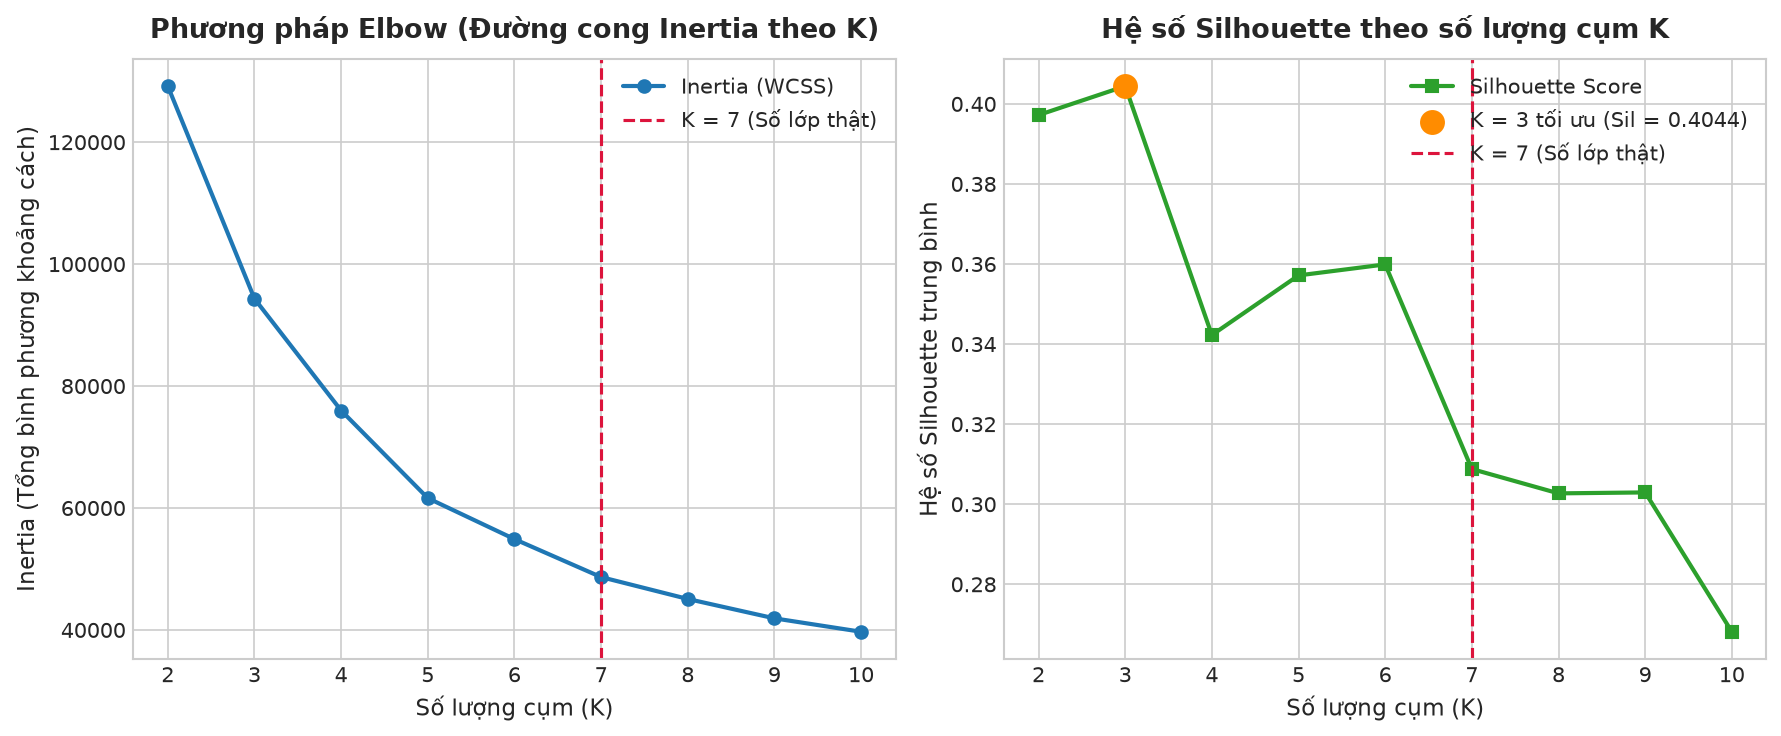

In [ ]:
print("=" * 70)
print("BƯỚC 11: PHÂN CỤM K-MEANS (K = 2..10), ELBOW & SILHOUETTE")
print("=" * 70)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[ALL_FEATURES].copy())
print(f"- Dữ liệu chuẩn hóa đưa vào K-Means: {X_scaled.shape[0]:,} mẫu, {X_scaled.shape[1]} đặc trưng.")

kmeans_results = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    lbls = km.fit_predict(X_scaled)
    kmeans_results.append(
        {
            "k": k,
            "inertia": float(km.inertia_),
            "silhouette": float(silhouette_score(X_scaled, lbls)),
        }
    )

kmeans_df = pd.DataFrame(kmeans_results)
print("\n" + "-" * 55)
print(f"{'K':<6}{'Inertia (WCSS)':<22}{'Silhouette Score':<20}")
print("-" * 55)
for _, row in kmeans_df.iterrows():
    print(f"{int(row['k']):<6}{row['inertia']:<22.4f}{row['silhouette']:<20.4f}")
print("-" * 55)

best_sil_row = kmeans_df.loc[kmeans_df["silhouette"].idxmax()]
best_k = int(best_sil_row["k"])
best_sil = float(best_sil_row["silhouette"])
best_inertia = float(best_sil_row["inertia"])
k7_row = kmeans_df.loc[kmeans_df["k"] == 7].iloc[0]

print(f"\n=> K tối ưu theo Silhouette: K = {best_k} (Silhouette = {best_sil:.4f}, Inertia = {best_inertia:.4f}).")
print(f"=> Tại K = 7 (số lớp thật) : Silhouette = {k7_row['silhouette']:.4f}, Inertia = {k7_row['inertia']:.4f}.")

# Biểu đồ 09: Elbow & Silhouette
fig_es, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(
    kmeans_df["k"],
    kmeans_df["inertia"],
    marker="o",
    color="#1f77b4",
    linewidth=2,
    markersize=6,
    label="Inertia (WCSS)",
)
ax1.axvline(x=7, color="crimson", linestyle="--", linewidth=1.5, label="K = 7 (Số lớp thật)")
ax1.set_title("Phương pháp Elbow (Đường cong Inertia theo K)", fontsize=13, fontweight="bold", pad=10)
ax1.set_xlabel("Số lượng cụm (K)", fontsize=11)
ax1.set_ylabel("Inertia (Tổng bình phương khoảng cách)", fontsize=11)
ax1.set_xticks(kmeans_df["k"])
ax1.legend(loc="upper right", fontsize=10)

ax2.plot(
    kmeans_df["k"],
    kmeans_df["silhouette"],
    marker="s",
    color="#2ca02c",
    linewidth=2,
    markersize=6,
    label="Silhouette Score",
)
ax2.scatter(
    [best_k],
    [best_sil],
    color="darkorange",
    s=120,
    zorder=5,
    label=f"K = {best_k} tối ưu (Sil = {best_sil:.4f})",
)
ax2.axvline(x=7, color="crimson", linestyle="--", linewidth=1.5, label="K = 7 (Số lớp thật)")
ax2.set_title("Hệ số Silhouette theo số lượng cụm K", fontsize=13, fontweight="bold", pad=10)
ax2.set_xlabel("Số lượng cụm (K)", fontsize=11)
ax2.set_ylabel("Hệ số Silhouette trung bình", fontsize=11)
ax2.set_xticks(kmeans_df["k"])
ax2.legend(loc="upper right", fontsize=10)

plt.tight_layout()
out_es = os.path.join(OUTPUT_DIR, "09_elbow_silhouette.png")
fig_es.savefig(out_es, dpi=300, bbox_inches="tight")
print(f"\n- Đã lưu biểu đồ: '{out_es}' (DPI 300)")
plt.show()
plt.close(fig_es)

BƯỚC 12 & 13: ĐỐI CHIẾU K=7 VỚI 7 LỚP THẬT (CROSSTAB, ARI, PCA 2D)
- Chỉ số ARI tại K = 3 (K tối ưu Silhouette): 0.2976
- Chỉ số ARI tại K = 7 (Đối chiếu 7 lớp thật)   : 0.6669

BẢNG CHÉO (CROSSTAB) ĐỐI CHIẾU CỤM K-MEANS (K = 7) VÀ LỚP THỰC TẾ:
----------------------------------------------------------------------
Lớp thực tế  BARBUNYA  BOMBAY  CALI  DERMASON  HOROZ  SEKER  SIRA
Cụm 0               0       0     0      2912      2     52   192
Cụm 1              40       1   272        13    183      3    27
Cụm 2               9       0    26         7   1597      0    63
Cụm 3               0     520     0         0      0      0     0
Cụm 4            1141       1  1302         0     30      0     5
Cụm 5              18       0     2       115      0   1874    24
Cụm 6             114       0    28       499     48     98  2325
----------------------------------------------------------------------

Phân tích độ tinh khiết từng cụm (K = 7):
  + Cụm 0: 3,158 mẫu | Chiếm ưu thế: DERMA

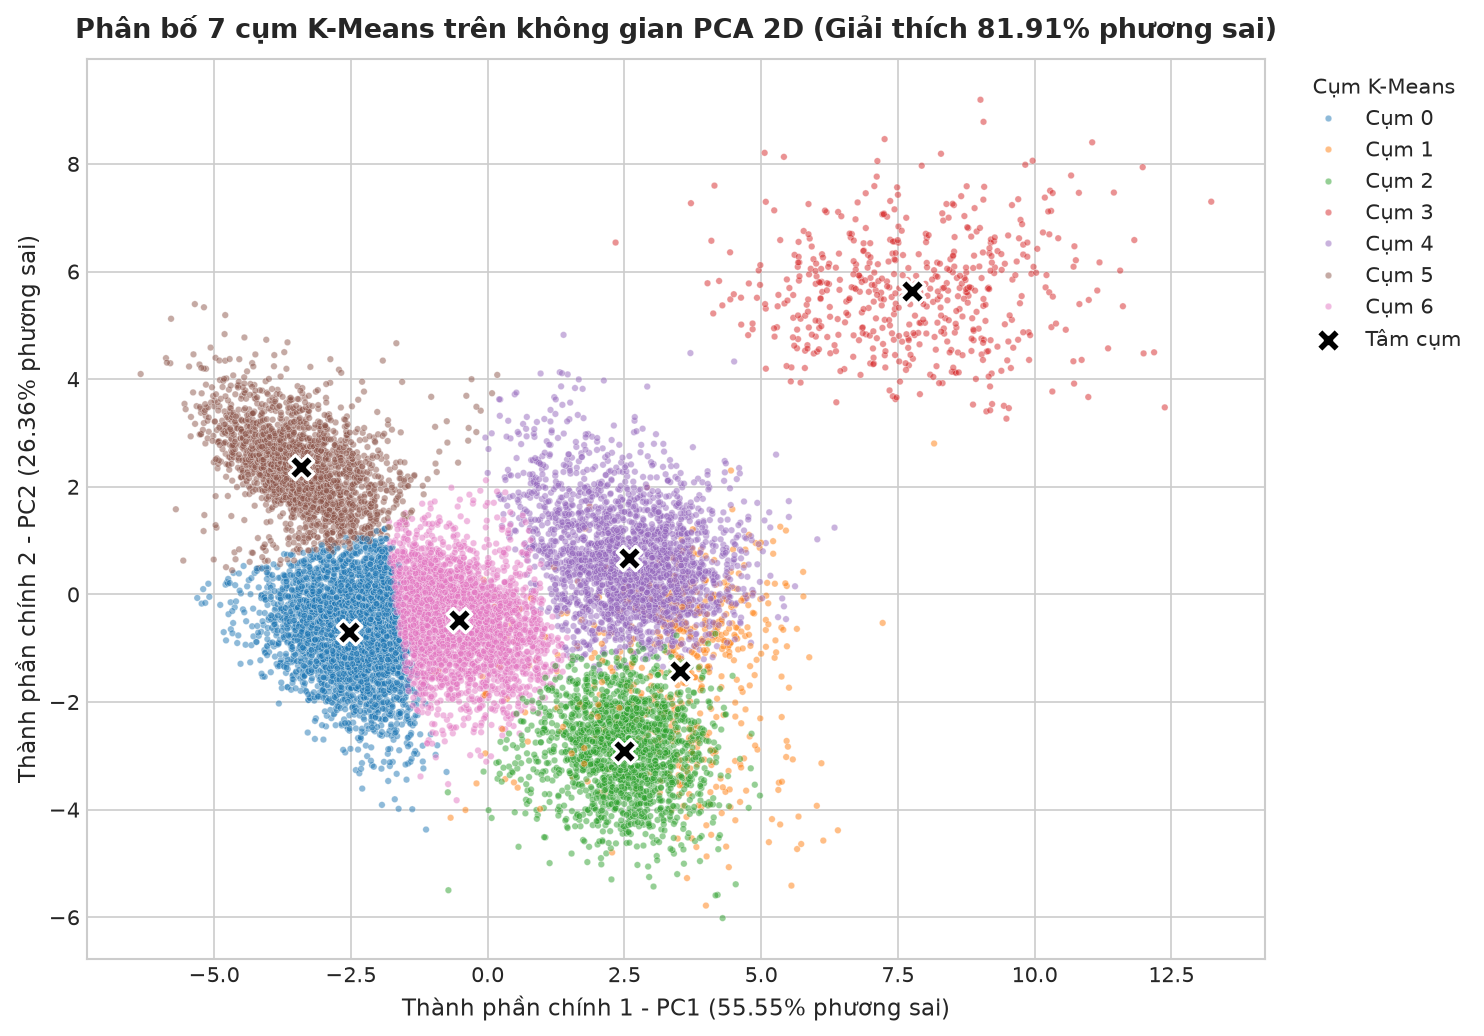

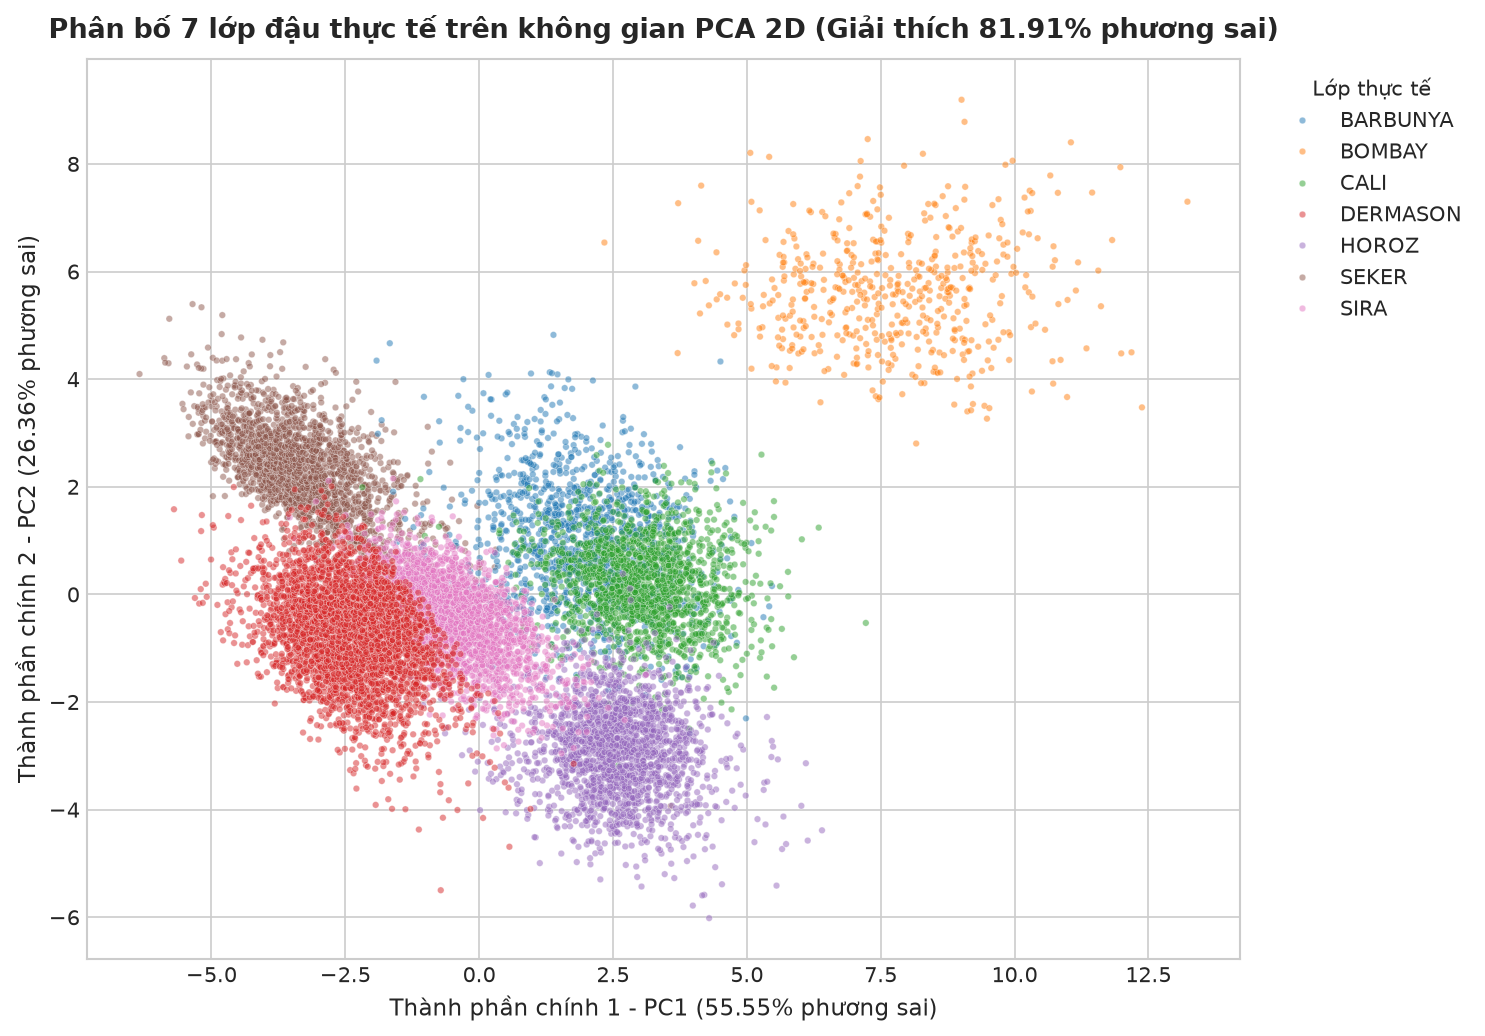

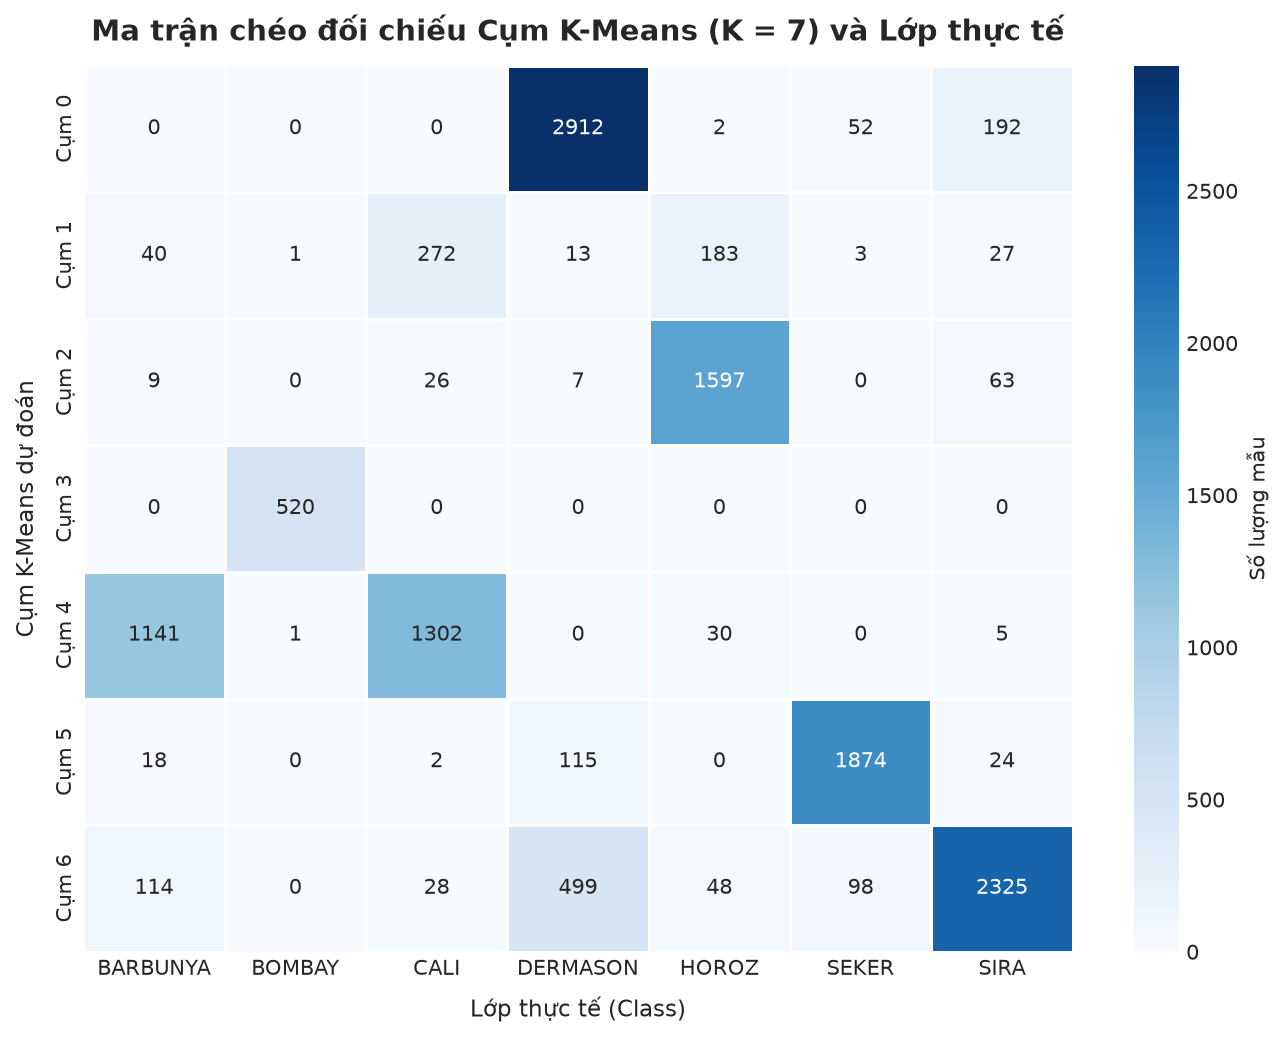

In [11]:
print("=" * 70)
print("BƯỚC 12 & 13: ĐỐI CHIẾU K=7 VỚI 7 LỚP THẬT (CROSSTAB, ARI, PCA 2D)")
print("=" * 70)

y_true_all = df_clean[CLASS_COLUMN]

# 1. Huấn luyện K-Means với K = 3 (tối ưu) và K = 7 (đối chiếu 7 giống đậu thật)
kmeans_3 = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
labels_k3 = kmeans_3.fit_predict(X_scaled)
ari_k3 = float(adjusted_rand_score(y_true_all, labels_k3))

kmeans_7 = KMeans(n_clusters=7, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans_7.fit_predict(X_scaled)
ari_k7 = float(adjusted_rand_score(y_true_all, cluster_labels))

print(f"- Chỉ số ARI tại K = {best_k} (K tối ưu Silhouette): {ari_k3:.4f}")
print(f"- Chỉ số ARI tại K = 7 (Đối chiếu 7 lớp thật)   : {ari_k7:.4f}")

cluster_names = [f"Cụm {i}" for i in range(7)]
crosstab_df = pd.crosstab(
    cluster_labels,
    y_true_all,
    rownames=["Cụm dự đoán"],
    colnames=["Lớp thực tế"],
)
crosstab_df.index = cluster_names

print("\nBẢNG CHÉO (CROSSTAB) ĐỐI CHIẾU CỤM K-MEANS (K = 7) VÀ LỚP THỰC TẾ:")
print("-" * 70)
print(crosstab_df.to_string())
print("-" * 70)

print("\nPhân tích độ tinh khiết từng cụm (K = 7):")
total_cls_counts = y_true_all.value_counts()
for c_name in cluster_names:
    row = crosstab_df.loc[c_name]
    top_cls = row.idxmax()
    top_cnt = int(row[top_cls])
    tot_cnt = int(row.sum())
    purity = (top_cnt / tot_cnt) * 100
    coverage = (top_cnt / total_cls_counts[top_cls]) * 100
    print(
        f"  + {c_name}: {tot_cnt:>5,} mẫu | Chiếm ưu thế: {top_cls:<10} "
        f"({top_cnt:>5,} mẫu | Độ tinh khiết: {purity:>6.2f}% | Bao phủ lớp: {coverage:>6.2f}%)"
    )

# 2. Chiếu PCA 2D và vẽ Biểu đồ 11 & 12 (PCA Cụm K-Means vs. Lớp thật)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
var_tot = var_pc1 + var_pc2
centers_pca = pca.transform(kmeans_7.cluster_centers_)

print(f"\n- Tỷ lệ phương sai giải thích PCA 2D: PC1 = {var_pc1:.2f}%, PC2 = {var_pc2:.2f}% (Tổng = {var_tot:.2f}%).")

# Biểu đồ 11_pca_cum.png
fig_p1, ax_p1 = plt.subplots(figsize=(10, 7))
pca_cluster_df = pd.DataFrame(
    {"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Cụm": [f"Cụm {c}" for c in cluster_labels]}
)
sns.scatterplot(
    data=pca_cluster_df,
    x="PC1",
    y="PC2",
    hue="Cụm",
    hue_order=cluster_names,
    palette="tab10",
    alpha=0.5,
    s=10,
    ax=ax_p1,
)
ax_p1.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c="black",
    marker="X",
    s=140,
    edgecolors="white",
    linewidths=1.5,
    zorder=10,
    label="Tâm cụm",
)
ax_p1.set_title(
    f"Phân bố 7 cụm K-Means trên không gian PCA 2D (Giải thích {var_tot:.2f}% phương sai)",
    fontsize=13,
    fontweight="bold",
    pad=10,
)
ax_p1.set_xlabel(f"Thành phần chính 1 - PC1 ({var_pc1:.2f}% phương sai)", fontsize=11)
ax_p1.set_ylabel(f"Thành phần chính 2 - PC2 ({var_pc2:.2f}% phương sai)", fontsize=11)
ax_p1.legend(title="Cụm K-Means", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)
plt.tight_layout()
out_p1 = os.path.join(OUTPUT_DIR, "11_pca_cum.png")
fig_p1.savefig(out_p1, dpi=300, bbox_inches="tight")
print(f"- Đã lưu biểu đồ: '{out_p1}' (DPI 300)")
plt.show()
plt.close(fig_p1)

# Biểu đồ 12_pca_lop_that.png
fig_p2, ax_p2 = plt.subplots(figsize=(10, 7))
pca_class_df = pd.DataFrame(
    {"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Lớp thực tế": y_true_all.values}
)
sns.scatterplot(
    data=pca_class_df,
    x="PC1",
    y="PC2",
    hue="Lớp thực tế",
    hue_order=CLASS_NAMES,
    palette=CLASS_COLOR_MAP,
    alpha=0.5,
    s=10,
    ax=ax_p2,
)
ax_p2.set_title(
    f"Phân bố 7 lớp đậu thực tế trên không gian PCA 2D (Giải thích {var_tot:.2f}% phương sai)",
    fontsize=13,
    fontweight="bold",
    pad=10,
)
ax_p2.set_xlabel(f"Thành phần chính 1 - PC1 ({var_pc1:.2f}% phương sai)", fontsize=11)
ax_p2.set_ylabel(f"Thành phần chính 2 - PC2 ({var_pc2:.2f}% phương sai)", fontsize=11)
ax_p2.legend(title="Lớp thực tế", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)
plt.tight_layout()
out_p2 = os.path.join(OUTPUT_DIR, "12_pca_lop_that.png")
fig_p2.savefig(out_p2, dpi=300, bbox_inches="tight")
print(f"- Đã lưu biểu đồ: '{out_p2}' (DPI 300)")
plt.show()
plt.close(fig_p2)

# Biểu đồ Heatmap Crosstab (10_crosstab_cum_lop.png)
fig_ct, ax_ct = plt.subplots(figsize=(9, 7))
sns.heatmap(
    crosstab_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=0.5,
    ax=ax_ct,
    cbar_kws={"label": "Số lượng mẫu"},
)
ax_ct.set_title(
    "Ma trận chéo đối chiếu Cụm K-Means (K = 7) và Lớp thực tế",
    fontsize=14,
    fontweight="bold",
    pad=12,
)
ax_ct.set_xlabel("Lớp thực tế (Class)", fontsize=11, labelpad=8)
ax_ct.set_ylabel("Cụm K-Means dự đoán", fontsize=11, labelpad=8)
ax_ct.tick_params(axis="both", labelsize=10)
plt.tight_layout()
out_ct = os.path.join(OUTPUT_DIR, "10_crosstab_cum_lop.png")
fig_ct.savefig(out_ct, dpi=300, bbox_inches="tight")
print(f"- Đã lưu biểu đồ: '{out_ct}' (DPI 300)")
plt.show()
plt.close(fig_ct)

### 5.2. Kết luận định lượng giải quyết RQ2

1. **Số cụm tối ưu của K-Means là $K = 3$ (`Silhouette Score = 0.4044`, `Inertia = 94.331,7346`):**
   - Đường cong Elbow bắt đầu gãy và thoải dần từ $K = 3..5$, đồng thời hệ số Silhouette đạt đỉnh tuyệt đối tại $K = 3$. Điều này chứng minh trong không gian 16 chiều không nhãn, dữ liệu đậu khô tự nhiên phân tách thành **3 đại nhóm hình thái rõ nét**: (1) Nhóm hạt khổng lồ (`BOMBAY`), (2) Nhóm hạt lớn/thuôn dài (`CALI`, `BARBUNYA`, `HOROZ`), và (3) Nhóm hạt vừa và nhỏ (`DERMASON`, `SIRA`, `SEKER`).
2. **Độ khớp với 7 loại đậu thật đạt mức khá cao (`ARI = 0.6669` tại $K = 7$):**
   - **Điểm khớp xuất sắc:** K-Means phân tách thuần khiết **100,00%** giống `BOMBAY` (`Cụm 3`: 520/520 mẫu, bao phủ 99,62% lớp), đồng thời tái tạo 3 cụm có độ tinh khiết trên 92% là `HOROZ` (`Cụm 2`: 93,83%), `DERMASON` (`Cụm 0`: 92,21%) và `SEKER` (`Cụm 5`: 92,18%).
   - **Điểm giao thoa:** Do đặc tính hình cầu của khoảng cách Euclidean, K-Means gộp chung 2 giống hạt lớn bầu dục là `CALI` (1.302 mẫu) và `BARBUNYA` (1.141 mẫu) vào `Cụm 4` (và chia một phần sang `Cụm 1`), đồng thời có sự giao thoa tự nhiên giữa `SIRA` và `DERMASON` tại `Cụm 6` (499 mẫu `DERMASON` lẫn trong cụm của `SIRA`).
   - Trên không gian **PCA 2D** (bảo toàn **81,91%** phương sai), cấu trúc phân bố giữa 7 cụm K-Means và 7 nhãn thật thể hiện mức tương đồng hình học cao.

## Phần 6: Tổng kết & Thảo luận

### 6.1. Tóm lược kết quả thực nghiệm toàn dự án
| Hạng mục | Kết quả thực tế ghi nhận |
|---|---|
| **Dữ liệu sau tiền xử lý** | `13.543` mẫu sạch (loại 68 dòng trùng từ `13.611` mẫu gốc; 0 thiếu; giữ nguyên `3.004` mẫu ngoại lai IQR [22,18%]) |
| **Đa cộng tuyến (EDA)** | Phát hiện `21` cặp đặc trưng có $|r| > 0.9$ (cao nhất `Area` – `ConvexArea`: $r = 0.9999$) |
| **Mô hình tốt nhất (5-fold CV)** | `Decision Tree - Hình dạng (8 đặc trưng)` (`F1-macro CV = 0.9128 ± 0.0072`, `Acc CV = 0.8984 ± 0.0072`) |
| **Kết quả kiểm tra (Test 20%)** | `Accuracy = 0.8963 (89,63%)` / `F1-macro = 0.9099 (90,99%)` (`BOMBAY` đạt `1.0000`) |
| **Trả lời RQ1** | **Nhóm Hình dạng** vượt trội (`59,95%` Gini Importance; tăng +14,37% trên `GaussianNB`, +2,50% trên `Decision Tree`) |
| **Trả lời RQ2** | $K$ tối ưu là **$K = 3$** (`Silhouette = 0.4044`); tại $K = 7$ đạt **`ARI = 0.6669`**, PCA 2D giải thích **`81,91%`** phương sai |

### 6.2. Đánh giá ưu & nhược điểm các thuật toán đã sử dụng
1. **`GaussianNB`:**
   - *Ưu điểm:* Huấn luyện tức thời, cực kỳ hiệu quả khi các đặc trưng ít tương quan dư thừa (đạt `F1-macro CV = 0.9062` trên Nhóm Hình dạng).
   - *Nhược điểm:* Rất nhạy cảm với hiện tượng đa cộng tuyến. Khi dùng Nhóm Kích thước (chứa nhiều cặp $r > 0.95$), mô hình đếm lặp thông tin dẫn tới giảm hiệu năng còn `0.7625`.
2. **`DecisionTreeClassifier`:**
   - *Ưu điểm:* Không cần chuẩn hóa dữ liệu, miễn nhiễm tốt với đa cộng tuyến và các ngoại lai ở biên nhờ cơ chế chia nhánh đơn biến, cung cấp khả năng giải thích trực quan qua `feature_importances_`.
   - *Nhược điểm:* Khi không giới hạn độ sâu (`max_depth=None`), cây có thể học quá khớp nhẹ tại vùng giao thoa giữa `DERMASON` và `SIRA` (Test Acc `0.8963` vs Train CV `0.8984`).
3. **`KMeans`:**
   - *Ưu điểm:* Nhanh, khám phá chuẩn xác cấu trúc phân tầng tự nhiên ($K = 3$) và bóc tách hoàn hảo giống hạt đặc thù như `BOMBAY` (`100%`) mà không cần bất kỳ nhãn nào.
   - *Nhược điểm:* Giả định cụm hình cầu làm thuật toán khó phân tách hai giống hạt lớn có phân bố dạng elip nối tiếp nhau là `CALI` và `BARBUNYA`.

### 6.3. Hướng phát triển (nếu mở rộng ngoài phạm vi đồ án)
- Áp dụng **cắt tỉa cây quyết định (`ccp_alpha`, `max_depth`)** hoặc các mô hình tập hợp (**Random Forest**, **XGBoost**) nhằm giảm tỷ lệ nhầm lẫn ở cặp `DERMASON` – `SIRA`.
- Sử dụng **PCA** hoặc loại bỏ biến đồng tuyến tính cực cao ($r > 0.99$) trước khi đưa vào `GaussianNB`.
- Thử nghiệm **Gaussian Mixture Models (GMM)** hoặc phân cụm theo mật độ (**HDBSCAN**) để mô hình hóa tốt hơn các cụm dạng elip chồng lấn như `CALI` và `BARBUNYA`.